# Overnight base load in Germany: weekly forecasts two years ahead

**What we forecast.** The weekly mean of German electricity load in the **overnight hours (00:00 to 05:59, Berlin time)**, in weeks that end on Tuesday. Overnight load is the floor of the daily cycle. Must-run plant has to cover it, and storage is charged during it, so a two-year forecast of it helps plan both.

**How the notebook is organised.** The code lives in the package `src/nightload/` (one module per job). This notebook calls it in nine checkpoints:

| Checkpoint | What it does | Brief part |
|---|---|---|
| 1 | Data, weekly and daily series, plots, decomposition, stationarity tests | Part 1 |
| 2 | Mean, naive, seasonal naive and drift benchmarks | Part 2 |
| 3 | SARIMA: all 147 (p, d, q) orders by AIC, residual checks, 95% interval | Part 3 |
| 4 | SARIMAX with temperature and holidays | Part 4 |
| 5 | Random forest and gradient boosting | Part 5 |
| 6 | Hourly LSTM in PyTorch | Part 6 |
| 7 | Comparison table, significance tests, master plot | Parts 2 to 6 |
| 8 | Extra checks: improvement rule, leakage test, model size, operational shortlist | Part 7 |
| 9 | Output files | Part 9 |

**Test window:** the last 104 weeks. Everything that learns from data (scalers, profiles, hyper-parameters, model orders) uses the training weeks only.

## Setup

The first cell finds the repository root, so the notebook runs from `notebooks/`, from the root, or on Colab. The second installs only missing packages.

In [1]:
# The analysis code is a package in src/, so the notebook first locates the repo root:
# walk up from the working directory until src/nightload appears.
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
# >>> STUDENT: after pushing to GitHub, paste the repository URL between the quotes. <<<
REPO_URL = ""  # e.g. "https://github.com/<your-account>/electricity-demand-forecast.git"

here = Path.cwd().resolve()
ROOT = next((p for p in (here, *here.parents) if (p / "src" / "nightload").is_dir()), None)
if ROOT is None and IN_COLAB and REPO_URL:
    subprocess.run(["git", "clone", "-q", REPO_URL, "nightload_repo"], check=True)
    ROOT = Path("nightload_repo").resolve()
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the repository, or set REPO_URL on Colab.")
sys.path.insert(0, str(ROOT / "src"))
print("Package folder found: src/nightload")

Package folder found: src/nightload


In [2]:
# Colab already ships pandas, statsmodels, scikit-learn and torch, so only the gaps are
# installed and a local environment built from requirements.txt is left alone.
import importlib.util

PIP_NAMES = {"holidays": "holidays", "statsmodels": "statsmodels", "sklearn": "scikit-learn",
             "torch": "torch", "requests": "requests", "joblib": "joblib"}
missing = [pip for module, pip in PIP_NAMES.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Missing packages installed:", missing or "none")

Missing packages installed: none


In [3]:
# statsmodels prints many harmless optimiser warnings during order searches. Only those
# categories are silenced, so any other warning still shows up.
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning

from nightload import benchmarks as bm
from nightload import config as cfg
from nightload import data, features, lstm, plotting, sarima, stationarity, tree_models
from nightload import evaluation as ev
from nightload.narrative import format_fact, render_findings

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=ValueWarning)
warnings.filterwarnings("ignore", message=".*Non-(invertible|stationary) starting.*")

cfg.ensure_dirs()
plotting.apply_house_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)

facts: dict = {}   # every number quoted in markdown or the README is stored here
timings: dict = {}  # wall-clock seconds per model family, for the model-size table
print("pandas", pd.__version__, "| torch", torch.__version__, "| numpy", np.__version__)

pandas 2.2.3 | torch 2.13.0 | numpy 2.2.5


## Checkpoint 1 · Data and first look

**Loading.** The OPSD hourly file is read from `data/` (downloaded once if missing). Times are converted from UTC to Berlin time. The repeated autumn 02:00 hour is averaged and the missing spring 02:00 hour is interpolated. Load is converted from MW to GW.

In [4]:
# Overnight hours are defined on the local clock, so the hourly series is put on Berlin
# wall-clock time before any binning happens.
hourly = data.read_hourly_load()
facts["hours_total"] = len(hourly)
facts["hours_filled"] = int((~hourly["observed"]).sum())
facts["first_hour"] = str(hourly.index[0])
facts["last_hour"] = str(hourly.index[-1])
print(f"Hourly rows: {len(hourly):,}  from {hourly.index[0]} to {hourly.index[-1]} (local time)")
print(f"Hours filled by interpolation: {facts['hours_filled']}")
hourly.describe().T

Hourly rows: 50,401  from 2015-01-01 01:00:00 to 2020-10-01 01:00:00 (local time)
Hours filled by interpolation: 6


,count,mean,std,min,25%,50%,75%,max
load_gw,50401.0,55.492,10.016,31.307,47.106,55.092,64.309,77.549


**Weekly series.** A week runs from Wednesday 00:00 to Tuesday 23:59 and has 42 overnight hours. **A week is kept only if at least 40 of them were observed**, which drops the partial first and last weeks. The plain all-hours weekly mean is built on the same weeks for comparison.

In [5]:
# Printing both weekly series side by side shows how far the overnight floor sits below
# the usual weekly mean, which is the reason for using this lens at all.
lens_weeks = data.bin_overnight_weeks(hourly)
plain_weeks = data.bin_all_hour_weeks(hourly)
daily = data.bin_days(hourly)

side = pd.DataFrame({"overnight lens (GW)": lens_weeks["overnight_gw"].describe(),
                     "all-hours mean (GW)": plain_weeks.reindex(lens_weeks.index).describe()})
facts["n_weeks"] = len(lens_weeks)
facts["lens_mean"] = lens_weeks["overnight_gw"].mean()
facts["plain_mean"] = plain_weeks.reindex(lens_weeks.index).mean()
facts["lens_gap"] = facts["plain_mean"] - facts["lens_mean"]
print(f"Weeks kept: {len(lens_weeks)} ({lens_weeks.index[0].date()} to {lens_weeks.index[-1].date()})")
print("Overnight hours per kept week:", lens_weeks["night_hours"].value_counts().to_dict())
print(f"Daily rows: {len(daily)}")
side

Weeks kept: 299 (2015-01-13 to 2020-09-29)
Overnight hours per kept week: {42: 293, 41: 6}
Daily rows: 2100


,overnight lens (GW),all-hours mean (GW)
count,299.000,299.000
mean,44.903,55.507
std,3.506,3.750
min,37.901,45.337
25%,42.140,52.782
50%,44.236,54.911
75%,47.842,58.809
max,53.545,63.268


**Temperature and holidays.** The brief uses Berlin temperature, so Berlin is kept as the baseline. The main models use a **population-weighted mean of five cities** (Berlin, Hamburg, Munich, Cologne, Frankfurt), because demand is spread across the country. Checkpoint 4 compares the two. Daily temperature comes from the Open-Meteo archive and is cached in `data/temperature_five_cities_daily.csv`. Heating degree days use a **16 °C base** and cooling degree days a **20 °C base**. Holidays are German national public holidays, counted per week.

In [6]:
# Berlin alone is the brief's baseline; the five-city index is the extension used by the
# main models, since one city misses the north-south spread of German winters.
city_temps = data.gather_city_temperatures()
weekly_wx = data.weekly_weather(city_temps["weighted_c"])
weekly_wx_berlin = data.weekly_weather(city_temps["Berlin"])
holiday_daily = data.national_holiday_days("2014-12-01", "2020-10-31")
holiday_weeks = data.holidays_per_week("2014-12-01", "2020-10-31")

frame = features.assemble_weekly_frame(lens_weeks, plain_weeks, weekly_wx, holiday_weeks)
train_df, test_df = features.split_weeks(frame)
y_train, y_test = train_df["overnight_gw"], test_df["overnight_gw"]
TEST_START = test_df.index[0]
facts.update(train_weeks=len(train_df), test_weeks=len(test_df),
             train_end=str(train_df.index[-1].date()), test_first=str(TEST_START.date()),
             test_last=str(test_df.index[-1].date()),
             temp_load_corr=frame[["temp_c", "overnight_gw"]].corr().iloc[0, 1])
print(f"Training weeks: {len(train_df)} (to {facts['train_end']}), test weeks: {len(test_df)} "
      f"({facts['test_first']} to {facts['test_last']})")
print(f"Correlation of weekly temperature with overnight load: {facts['temp_load_corr']:.3f}")
display(data.city_weight_table().round(3))
frame.head()

Training weeks: 195 (to 2018-10-02), test weeks: 104 (2018-10-09 to 2020-09-29)
Correlation of weekly temperature with overnight load: -0.740


,city,lat,lon,population_m,weight
0,Berlin,52.52,13.41,3.60,0.411
1,Hamburg,53.55,9.99,1.80,0.206
2,Munich,48.14,11.58,1.50,0.171
3,Cologne,50.94,6.96,1.10,0.126
4,Frankfurt,50.11,8.68,0.75,0.086


,overnight_gw,all_hours_gw,temp_c,hdd,cdd,holidays,woy
local_time,,,,,,,
2015-01-13,45.931,57.921,5.487,73.588,0.0,0.0,3
2015-01-20,46.177,57.643,2.584,93.915,0.0,0.0,4
2015-01-27,47.980,58.758,0.473,108.687,0.0,0.0,5
2015-02-03,47.803,58.807,0.287,109.991,0.0,0.0,6
2015-02-10,49.050,59.345,-0.284,113.989,0.0,0.0,7


### First plots

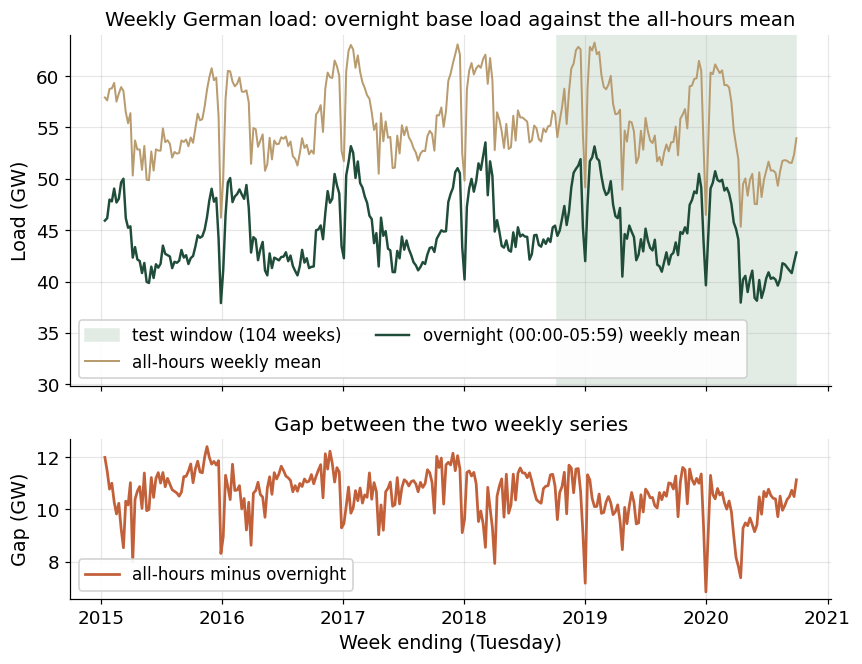

In [7]:
fig = plotting.plot_lens_against_plain(frame, TEST_START)
plotting.save_png(fig, "01_overnight_vs_all_hours")
plt.show()

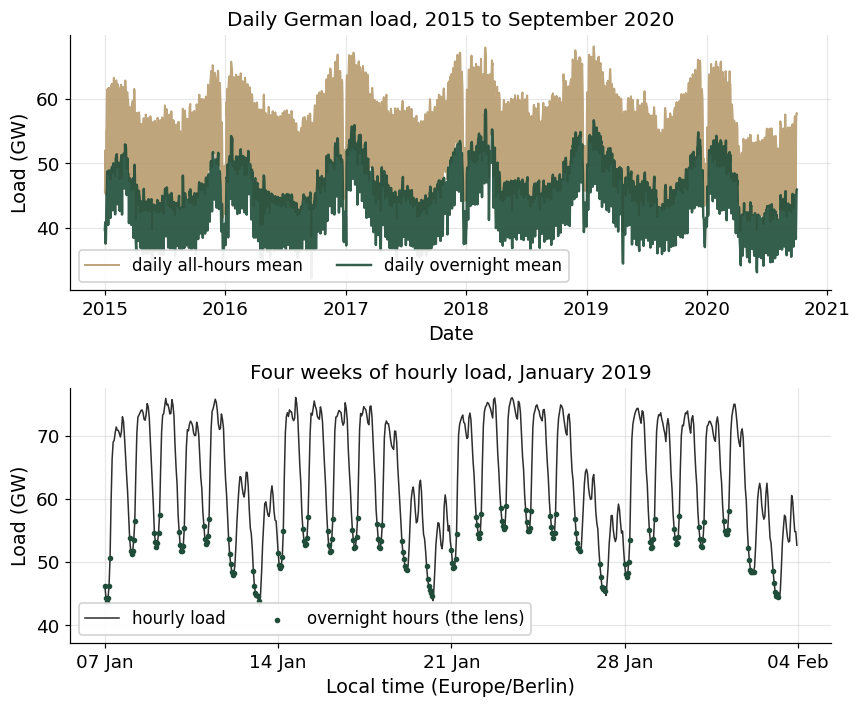

In [8]:
fig = plotting.plot_daily_and_hourly(daily, hourly["load_gw"])
plotting.save_png(fig, "02_daily_and_hourly")
plt.show()

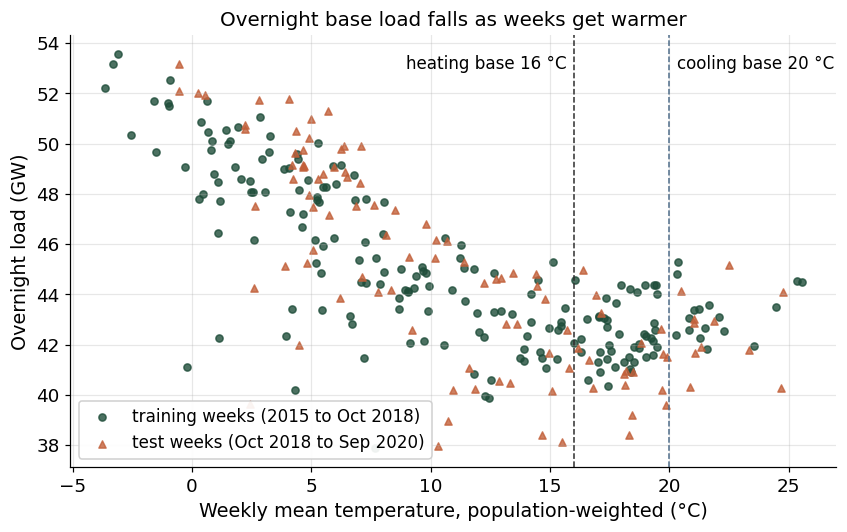

In [9]:
fig = plotting.plot_temperature_response(frame, TEST_START)
plotting.save_png(fig, "03_temperature_response")
plt.show()

In [10]:
display(Markdown(render_findings(r"""
**What the plots show.** The overnight series averages **«lens_mean» GW**, about **«lens_gap» GW below** the all-hours mean («plain_mean» GW). Both share the winter peak, the Christmas dip and the 2020 lockdown dip. **Overnight load falls as weeks get warmer** (correlation **«temp_load_corr»**), with almost no rise in hot weeks, so cooling degree days should matter little.
""", facts)))


**What the plots show.** The overnight series averages **44.90 GW**, about **10.60 GW below** the all-hours mean (55.51 GW). Both share the winter peak, the Christmas dip and the 2020 lockdown dip. **Overnight load falls as weeks get warmer** (correlation **-0.74**), with almost no rise in hot weeks, so cooling degree days should matter little.


### Decomposition

**Weekly series:** STL with period 52. **Daily series:** MSTL with periods 7 (weekday) and 365 (year). Strength near 1 means a component dominates.

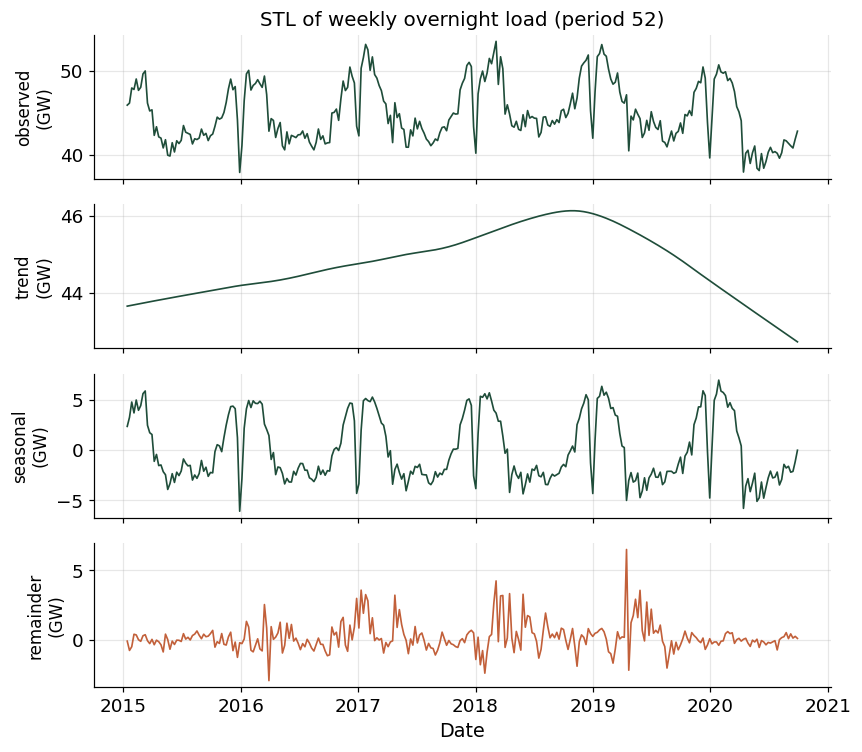

,seasonal,trend
strength,0.901,0.484


In [11]:
weekly_parts = stationarity.stl_weekly(frame["overnight_gw"])
fig = plotting.plot_decomposition(weekly_parts, "STL of weekly overnight load (period 52)")
plotting.save_png(fig, "04_stl_weekly")
plt.show()
weekly_strength = stationarity.component_strength(weekly_parts)
facts["strength_weekly_season"] = weekly_strength["seasonal"]
facts["strength_weekly_trend"] = weekly_strength["trend"]
weekly_strength.to_frame().T

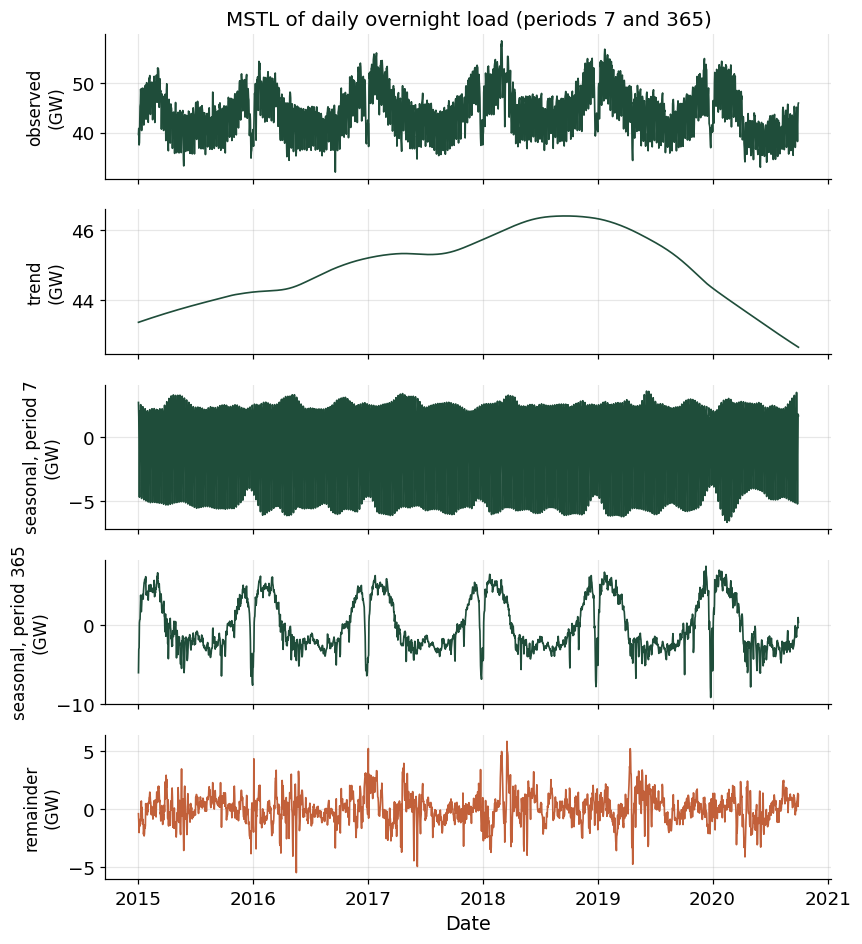

,seasonal_7,seasonal_365,trend
strength,0.829,0.869,0.405


In [12]:
daily_parts = stationarity.mstl_daily(daily["overnight_gw"])
fig = plotting.plot_decomposition(daily_parts, "MSTL of daily overnight load (periods 7 and 365)")
plotting.save_png(fig, "05_mstl_daily")
plt.show()
daily_strength = stationarity.component_strength(daily_parts)
facts["strength_daily_7"] = daily_strength["seasonal_7"]
facts["strength_daily_365"] = daily_strength["seasonal_365"]
daily_strength.to_frame().T

In [13]:
display(Markdown(render_findings(r"""
**Components.** A strong annual cycle in both series (weekly seasonal strength **«strength_weekly_season»**, daily annual strength **«strength_daily_365»**) and a weekly cycle in the daily series (strength **«strength_daily_7»**). The trend rises to late 2018 and then falls through the test window, faster in the 2020 lockdown.
""", facts)))


**Components.** A strong annual cycle in both series (weekly seasonal strength **0.90**, daily annual strength **0.87**) and a weekly cycle in the daily series (strength **0.83**). The trend rises to late 2018 and then falls through the test window, faster in the 2020 lockdown.


### Stationarity tests

**ADF** (null: unit root) and **KPSS** (null: stationary) on the level, the first difference, the seasonal difference and both. Weekly season = 52, daily season = 7.

In [14]:
# ADF and KPSS have opposite nulls: agreement between them is stronger evidence than
# either p-value on its own.
weekly_battery = stationarity.adf_kpss_verdicts(frame["overnight_gw"], cfg.SEASON)
daily_battery = stationarity.adf_kpss_verdicts(daily["overnight_gw"], 7)
facts["adf_p_level"] = weekly_battery.loc["level", "ADF_p"]
facts["adf_p_seasonal"] = weekly_battery.iloc[2]["ADF_p"]
facts["kpss_p_seasonal"] = weekly_battery.iloc[2]["KPSS_p"]
facts["adf_p_both"] = weekly_battery.iloc[3]["ADF_p"]
print("Weekly overnight series (season 52)")
display(weekly_battery.round(4))
print("Daily overnight series (season 7)")
display(daily_battery.round(4))

Weekly overnight series (season 52)


,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,verdict
series,,,,,,,
level,299,-4.323,4.000e-04,2,0.117,0.10,stationary (both agree)
first difference,298,-10.036,0.000e+00,4,0.028,0.10,stationary (both agree)
seasonal difference (52),247,-4.242,6.000e-04,2,1.212,0.01,ambiguous (tests disagree)
first + seasonal (52),246,-7.953,0.000e+00,9,0.039,0.10,stationary (both agree)


Daily overnight series (season 7)


,n,ADF_stat,ADF_p,ADF_lags,KPSS_stat,KPSS_p,verdict
series,,,,,,,
level,2100,-3.940,0.002,26,0.271,0.1,stationary (both agree)
first difference,2099,-12.887,0.000,26,0.027,0.1,stationary (both agree)
seasonal difference (7),2093,-10.799,0.000,26,0.020,0.1,stationary (both agree)
first + seasonal (7),2092,-16.454,0.000,22,0.020,0.1,stationary (both agree)


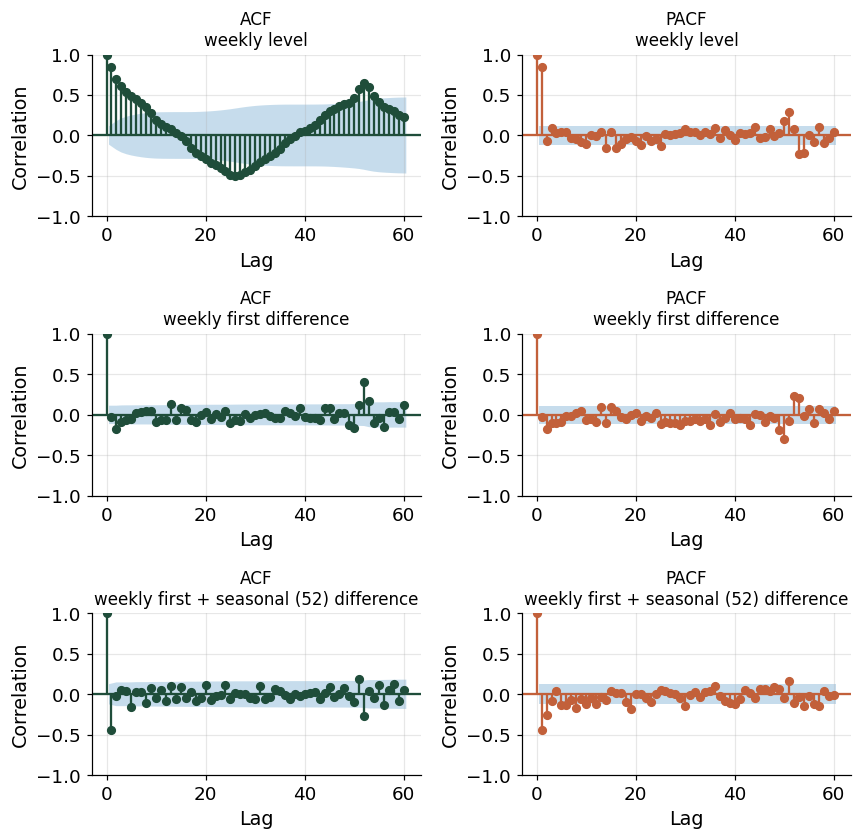

In [15]:
weekly_y = frame["overnight_gw"]
fig = plotting.plot_correlograms(
    {"weekly level": weekly_y,
     "weekly first difference": weekly_y.diff(),
     "weekly first + seasonal (52) difference": weekly_y.diff(52).diff()}, lags=60)
plotting.save_png(fig, "06_acf_pacf_weekly")
plt.show()

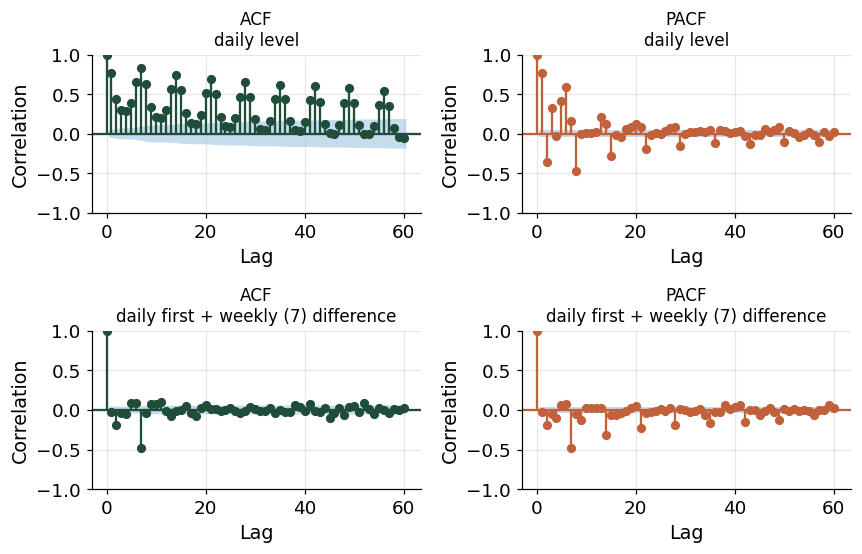

In [16]:
daily_y = daily["overnight_gw"]
fig = plotting.plot_correlograms(
    {"daily level": daily_y, "daily first + weekly (7) difference": daily_y.diff(7).diff()},
    lags=60)
plotting.save_png(fig, "07_acf_pacf_daily")
plt.show()

In [17]:
display(Markdown(render_findings(r"""
**Reading the tests.** The weekly level is already stationary on both tests (ADF p = **«adf_p_level»**): it moves around a strong annual cycle, not like a random walk. The seasonal difference alone is unclear (ADF p = «adf_p_seasonal», KPSS p = «kpss_p_seasonal»). The first plus seasonal difference is stationary on both (ADF p = «adf_p_both»). **So differencing is allowed here, not required.** d = 1, D = 1 is kept as a candidate and the AIC search in Checkpoint 3 decides.
""", facts)))


**Reading the tests.** The weekly level is already stationary on both tests (ADF p = **4.0e-4**): it moves around a strong annual cycle, not like a random walk. The seasonal difference alone is unclear (ADF p = 5.6e-4, KPSS p = 0.010). The first plus seasonal difference is stationary on both (ADF p = 3.1e-12). **So differencing is allowed here, not required.** d = 1, D = 1 is kept as a candidate and the AIC search in Checkpoint 3 decides.


## Checkpoint 2 · Benchmarks

Four simple forecasts over the 104 test weeks. **The seasonal naive (same week last year) is the benchmark every model is compared with.** MASE is scaled by the seasonal naive's in-sample error, so MASE above 1 means worse than that in-sample error. The seasonal naive also gets a 95% interval.

In [18]:
# one MASE scale for every model, computed on training weeks only
MASE_SCALE = ev.seasonal_scale(y_train)
assert ev.score_path(y_test, y_test, MASE_SCALE)["MASE"] == 0.0  # a perfect forecast scores 0

paths = bm.benchmark_paths(y_train, y_test.index)
bands = {"Seasonal naive": bm.seasonal_naive_band(y_train, y_test.index)}
bench_table = ev.league_table(y_test, paths, bands, MASE_SCALE)
facts["mase_scale"] = MASE_SCALE
facts["snaive_mase"] = bench_table.loc["Seasonal naive", "MASE"]
facts["snaive_mae"] = bench_table.loc["Seasonal naive", "MAE"]
print(f"MASE scale (in-sample seasonal-naive MAE): {MASE_SCALE:.3f} GW")
bench_table.round(3)

MASE scale (in-sample seasonal-naive MAE): 1.487 GW


,MAE,RMSE,MAPE_pct,MASE,Bias,Coverage95,DM_stat,DM_p,DM_p_bw4,MASE_vs_snaive
model,,,,,,,,,,
Seasonal naive,2.015,2.579,4.674,1.355,1.235,0.952,NaN,NaN,NaN,1.000
Mean,3.337,3.928,7.459,2.244,0.007,NaN,3.236,0.002,0.0,1.656
Drift,3.360,3.909,7.576,2.260,0.414,NaN,4.106,0.000,0.0,1.668
Naive,3.416,3.966,7.726,2.298,0.545,NaN,4.376,0.000,0.0,1.696


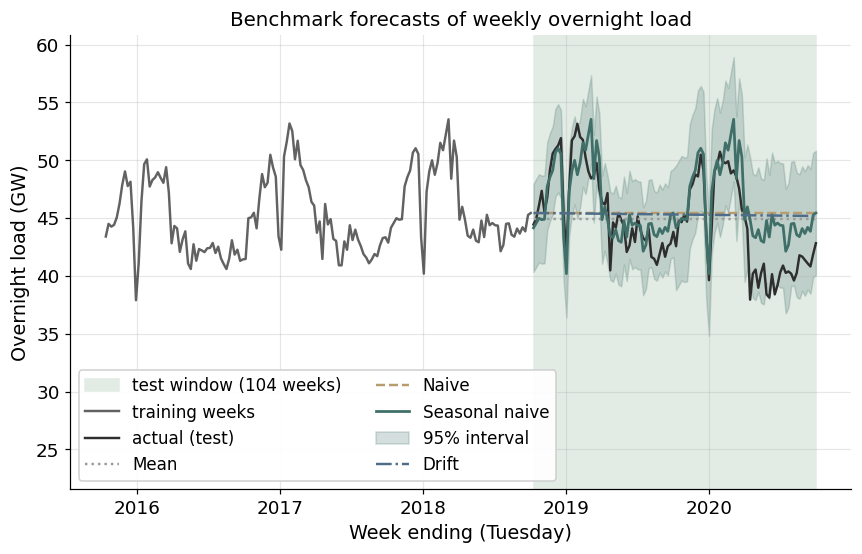

In [19]:
fig = plotting.plot_paths(y_train, y_test, paths, "Benchmark forecasts of weekly overnight load",
                          bands=bands, legend_cols=2)
plotting.save_png(fig, "08_benchmarks")
plt.show()

In [20]:
display(Markdown(render_findings(r"""
**Benchmarks.** **The seasonal naive is clearly the best benchmark (MASE «snaive_mase», MAE «snaive_mae» GW)**, because it is the only one that carries the annual cycle. It still over-forecasts the 2020 lockdown weeks, since it repeats a pre-pandemic year.
""", facts)))


**Benchmarks.** **The seasonal naive is clearly the best benchmark (MASE 1.355, MAE 2.01 GW)**, because it is the only one that carries the annual cycle. It still over-forecasts the 2020 lockdown weeks, since it repeats a pre-pandemic year.


## Checkpoint 3 · SARIMA: all 147 orders by AIC

**Every order with p 0 to 6, d 0 to 2 and q 0 to 6 is fitted (147 fits)**, with the seasonal part fixed at (0, 1, 1)[52]. Fits run in parallel and the full table is saved to `outputs/sarima_aic_grid.csv`. By default every run refits all 147 orders (`cfg.REFIT_SARIMA_GRID = True`).

**Selection:** the lowest AIC among fits that converged and have a stationary AR part. A second pass then compares three seasonal parts for the chosen order.

In [21]:
t0 = time.perf_counter()
grid, grid_meta = sarima.run_order_grid(y_train, reuse_cache=not cfg.REFIT_SARIMA_GRID)
grid = sarima.flag_admissible(grid)
timings["SARIMA grid (147 fits)"] = time.perf_counter() - t0
raw_best, chosen_order = sarima.pick_lowest_aic(grid)
facts.update(grid_admissible=int(grid["admissible"].sum()),
             grid_circle_seasonal=int((grid["ma_on_circle"] & (grid["seasonal_ma"] < -0.95)).sum()),
             grid_best_aic_d0=float(grid.loc[grid["d"] == 0, "aic"].min()),
             grid_best_aic_d1=float(grid.loc[grid["d"] == 1, "aic"].min()),
             grid_best_aic_d2=float(grid.loc[grid["d"] == 2, "aic"].min()))
facts.update(grid_fitted=grid_meta["orders_fitted"], grid_failed=grid_meta["orders_failed"],
             grid_not_converged=grid_meta["orders_not_converged"],
             grid_seconds=grid_meta["wall_seconds"], grid_ma_circle=int(grid["ma_on_circle"].sum()),
             raw_best=str(raw_best), chosen_order=str(chosen_order))
print(json.dumps(grid_meta, indent=1))
print(f"Lowest AIC overall: {raw_best}; lowest AIC that passes the checks: {chosen_order}")
print(f"Admissible fits (converged, stationary AR part): {facts['grid_admissible']} of {len(grid)}")
print(f"Fits with an MA root on the unit circle: {facts['grid_ma_circle']} "
      f"({facts['grid_circle_seasonal']} of them with a seasonal MA below -0.95)")
print("Best AIC by d:", {d: round(facts[f'grid_best_aic_d{d}'], 2) for d in range(3)})
grid.drop(columns="error").head(10).round(3)

Fitting 147 orders with seasonal (0, 1, 1, 52), maxiter=150, in parallel ...


   21/147 orders  elapsed    12 s  eta    72 s


   42/147 orders  elapsed    30 s  eta    74 s


   63/147 orders  elapsed    57 s  eta    76 s


   84/147 orders  elapsed   104 s  eta    78 s


  105/147 orders  elapsed   154 s  eta    62 s


  126/147 orders  elapsed   222 s  eta    37 s


  147/147 orders  elapsed   301 s  eta     0 s


{
 "fingerprint": "0d0a9b423c504aa1",
 "orders_fitted": 147,
 "orders_failed": 0,
 "orders_not_converged": 13,
 "seasonal_order": [
  0,
  1,
  1,
  52
 ],
 "maxiter": 150,
 "n_train_weeks": 195,
 "train_start": "2015-01-13",
 "train_end": "2018-10-02",
 "wall_seconds": 301.4,
 "statsmodels": "0.14.6"
}
Lowest AIC overall: (1, 1, 6); lowest AIC that passes the checks: (1, 1, 6)
Admissible fits (converged, stationary AR part): 129 of 147
Fits with an MA root on the unit circle: 131 (125 of them with a seasonal MA below -0.95)
Best AIC by d: {0: 293.26, 1: 289.17, 2: 291.32}


,p,d,q,aic,bic,converged,fit_ok,ar_root_min,ma_root_min,seasonal_ma,seconds,ma_on_circle,admissible
0,1,1,6,289.170,310.939,True,True,1.777,1.0,-1.000,14.50,True,True
1,4,1,6,289.630,318.656,True,True,1.039,1.0,-1.000,31.72,True,True
2,0,1,6,290.170,309.520,True,True,inf,1.0,-1.000,7.96,True,True
3,3,1,5,290.373,314.682,True,True,1.153,1.0,-1.000,20.96,True,True
4,2,1,6,290.430,314.619,True,True,1.711,1.0,-1.000,24.61,True,True
5,4,1,5,291.316,318.055,True,True,1.240,1.0,-1.000,17.39,True,True
6,3,2,6,291.321,317.795,False,True,1.191,1.0,-1.001,67.23,True,False
7,0,2,6,291.376,310.630,True,True,inf,1.0,-1.007,22.83,True,True
8,1,2,6,291.579,313.239,True,True,2.658,1.0,-1.000,33.29,True,True
9,2,1,4,292.023,311.564,True,True,1.212,1.0,-1.000,15.58,True,True


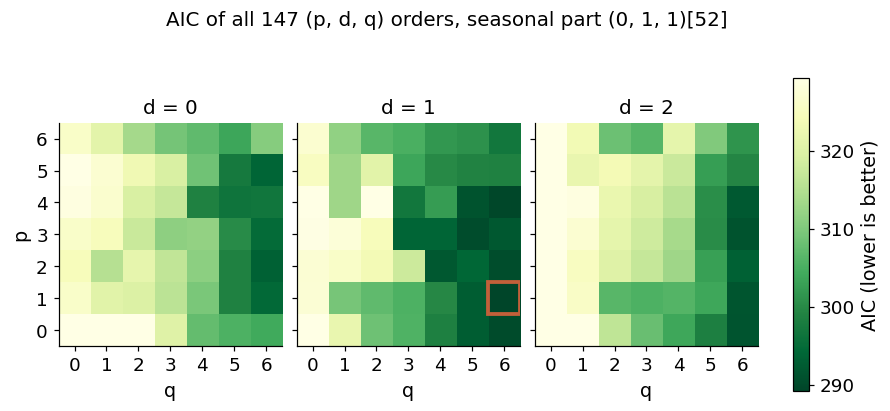

In [22]:
fig = plotting.plot_aic_surface(grid)
plotting.save_png(fig, "09_aic_surface")
plt.show()

In [23]:
# The grid fixed the seasonal part to keep 147 fits affordable; this checks that choice.
seasonal_check = sarima.compare_seasonal_parts(y_train, chosen_order)
best_seasonal = tuple(int(v) for v in seasonal_check.iloc[0]["seasonal_order"].strip("()").split(","))
facts["chosen_seasonal"] = str(best_seasonal)
seasonal_check.round(3)

,seasonal_order,P,Q,aic,converged
0,"(0, 1, 1, 52)",0,1,289.170,True
1,"(1, 1, 1, 52)",1,1,302.730,True
2,"(1, 1, 0, 52)",1,0,330.977,True


In [24]:
t0 = time.perf_counter()
sarima_fit = sarima.fit_final(y_train, chosen_order, best_seasonal)
timings["SARIMA final fit"] = time.perf_counter() - t0
facts["sarima_aic"] = sarima_fit.result.aic
facts["sarima_params"] = len(sarima_fit.result.params)
print(f"SARIMA{chosen_order}x{best_seasonal}  AIC {sarima_fit.result.aic:.2f}  "
      f"parameters {len(sarima_fit.result.params)}")
sarima_fit.result.summary().tables[1]

SARIMA(1, 1, 6)x(0, 1, 1, 52)  AIC 289.17  parameters 9


,coef,std err,z,P>|z|,[0.025,0.975]
ar.L1,0.5627,0.363,1.550,0.121,-0.149,1.274
ma.L1,-1.1369,139.288,-0.008,0.993,-274.137,271.863
ma.L2,0.1475,19.164,0.008,0.994,-37.413,37.708
ma.L3,0.1552,1.454,0.107,0.915,-2.695,3.005
ma.L4,-0.2440,23.121,-0.011,0.992,-45.560,45.072
ma.L5,-0.2568,11.004,-0.023,0.981,-21.824,21.311
ma.L6,0.3351,46.623,0.007,0.994,-91.044,91.715
ma.S.L52,-1.0002,926.015,-0.001,0.999,-1815.955,1813.955
sigma2,1.0454,1021.073,0.001,0.999,-2000.222,2002.312


### Do the MA terms undo the differencing?

If the MA coefficients sum to -1, they cancel the first difference. A seasonal MA of -1 cancels the seasonal difference. This cell checks both, refits with invertibility enforced, and prints the interval width at several horizons.

In [25]:
ma_check = sarima.ma_cancellation(sarima_fit)
refits = sarima.constrained_refits(y_train, chosen_order, best_seasonal)
inv_fit, both_fit = refits["invertible"], refits["stationary_and_invertible"]
inv_fc = sarima.project_forward(both_fit, y_test.index)
inv_score = ev.score_path(y_test, inv_fc["forecast"], MASE_SCALE, inv_fc["lower"], inv_fc["upper"])
sarima_band = sarima.project_forward(sarima_fit, y_test.index)
width = (sarima_band["upper"] - sarima_band["lower"]).to_numpy()
facts.update(ma_coef_sum=ma_check["ma_coefficient_sum"],
             ma_root_min=float(ma_check["ma_root_moduli"].min()),
             seasonal_ma_coef=float(ma_check["seasonal_ma"][0]),
             inv_aic=float(inv_fit.result.aic), both_aic=float(both_fit.result.aic),
             inv_mae=inv_score["MAE"],
             inv_mase=inv_score["MASE"], inv_cov=inv_score["Coverage95"],
             width_h1=width[0], width_h13=width[12], width_h52=width[51], width_h104=width[103])
print(f"Sum of the regular MA coefficients: {ma_check['ma_coefficient_sum']:.4f}")
print("Moduli of the regular MA roots:", np.round(ma_check["ma_root_moduli"], 3))
print(f"Seasonal MA coefficient: {ma_check['seasonal_ma'][0]:.4f}")
print(f"Regular difference cancelled: {ma_check['regular_difference_cancelled']}; "
      f"seasonal difference cancelled: {ma_check['seasonal_difference_cancelled']}")
print(f"AIC unenforced {sarima_fit.result.aic:.2f}; invertibility enforced {inv_fit.result.aic:.2f}; "
      f"stationarity and invertibility enforced {both_fit.result.aic:.2f}")
print(f"Fully constrained fit on the test window: MAE {inv_score['MAE']:.3f} GW, "
      f"MASE {inv_score['MASE']:.3f}, 95% coverage {inv_score['Coverage95']:.2f}")
print("95% interval width (GW) at h = 1, 13, 52, 104:", np.round(width[[0, 12, 51, 103]], 2))

Sum of the regular MA coefficients: -1.0000
Moduli of the regular MA roots: [1.    1.158 1.158 1.239 1.34  1.34 ]
Seasonal MA coefficient: -1.0002
Regular difference cancelled: True; seasonal difference cancelled: True
AIC unenforced 289.17; invertibility enforced 289.17; stationarity and invertibility enforced 519.73
Fully constrained fit on the test window: MAE 2.778 GW, MASE 1.868, 95% coverage 0.58
95% interval width (GW) at h = 1, 13, 52, 104: [4.67 5.66 5.52 5.62]


### Residual checks

The first d + p + 52 residuals are start-up values and are skipped. Ljung-Box is reported at lags 10 and 26.

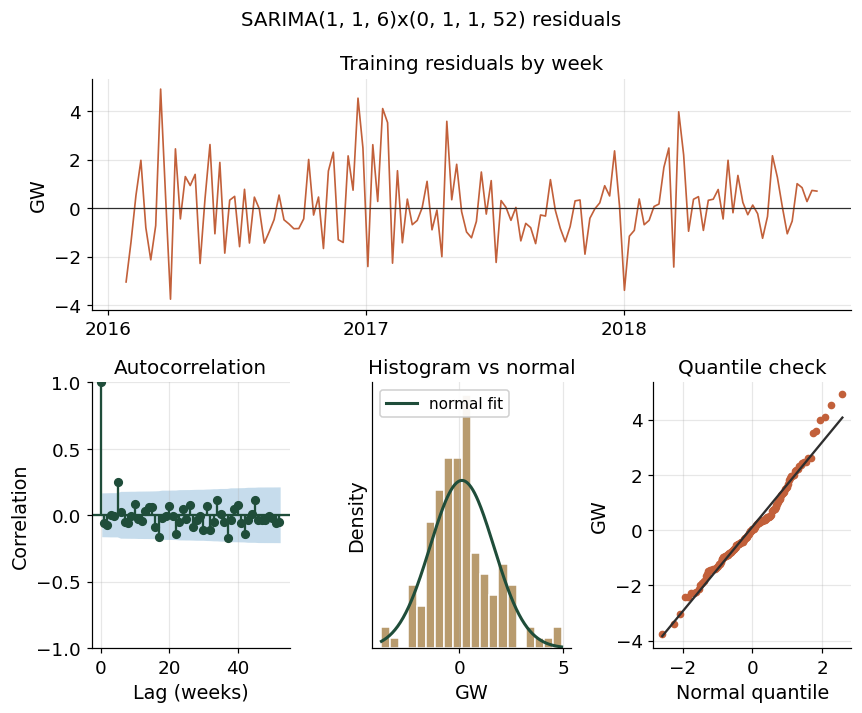

,Q,p_value
10,12.374,0.002
26,26.285,0.093


Jarque-Bera p = 0.0100; residual sd 1.535 GW, skew 0.51, excess kurtosis 0.71


In [26]:
sarima_diag = sarima.residual_checks(sarima_fit)
fig = plotting.plot_residual_panel(sarima_diag["residuals"],
                                   f"SARIMA{chosen_order}x{best_seasonal} residuals")
plotting.save_png(fig, "10_sarima_residuals")
plt.show()
lb = sarima_diag["ljung_box"]
facts.update(sarima_lb10_p=lb.loc[10, "p_value"], sarima_lb26_p=lb.loc[26, "p_value"],
             sarima_jb_p=sarima_diag["jarque_bera_p"], sarima_resid_sd=sarima_diag["std"],
             sarima_resid_skew=sarima_diag["skew"], sarima_resid_kurt=sarima_diag["excess_kurtosis"])
display(lb.round(4))
print(f"Jarque-Bera p = {sarima_diag['jarque_bera_p']:.4f}; residual sd {sarima_diag['std']:.3f} GW, "
      f"skew {sarima_diag['skew']:.2f}, excess kurtosis {sarima_diag['excess_kurtosis']:.2f}")

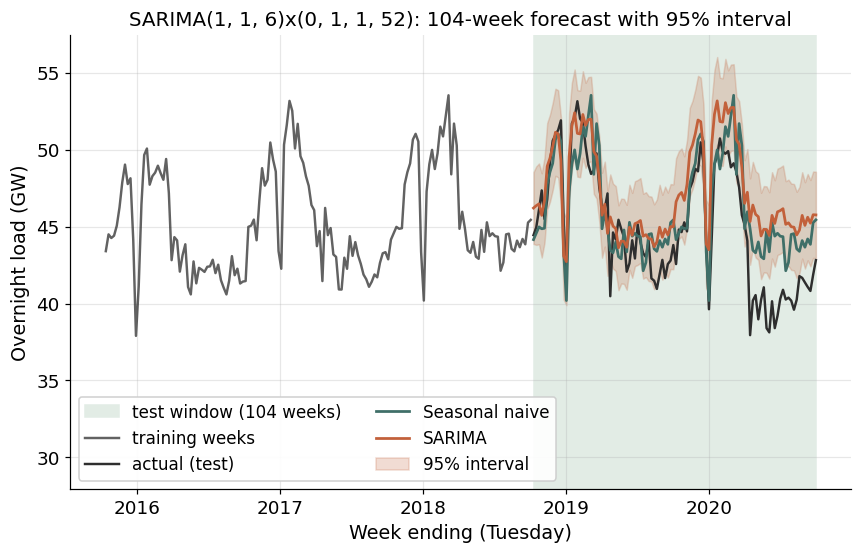

,MAE,RMSE,MAPE_pct,MASE,Bias,Coverage95
SARIMA,2.636,3.225,6.156,1.773,2.317,0.577


In [27]:
sarima_fc = sarima.project_forward(sarima_fit, y_test.index)
paths["SARIMA"] = sarima_fc["forecast"].rename("SARIMA")
bands["SARIMA"] = sarima_fc[["lower", "upper"]]
sarima_score = ev.score_path(y_test, paths["SARIMA"], MASE_SCALE, sarima_fc["lower"], sarima_fc["upper"])
facts.update(sarima_rmse=sarima_score["RMSE"], sarima_mase=sarima_score["MASE"],
             sarima_cov=sarima_score["Coverage95"], sarima_bias=sarima_score["Bias"])
fig = plotting.plot_paths(y_train, y_test, {"Seasonal naive": paths["Seasonal naive"],
                                            "SARIMA": paths["SARIMA"]},
                          f"SARIMA{chosen_order}x{best_seasonal}: 104-week forecast with 95% interval",
                          bands={"SARIMA": bands["SARIMA"]})
plotting.save_png(fig, "11_sarima_forecast")
plt.show()
pd.Series(sarima_score).round(3).to_frame("SARIMA").T

In [28]:
display(Markdown(render_findings(r"""
**SARIMA result.** All **«grid_fitted» orders** were fitted in «grid_seconds» s («grid_failed» failed, «grid_not_converged» did not converge, «grid_admissible» admissible). The chosen model is **SARIMA«chosen_order»x«chosen_seasonal»** with AIC **«sarima_aic»** (best AIC for d = 0, 1, 2: «grid_best_aic_d0», «grid_best_aic_d1», «grid_best_aic_d2»; AIC is not strictly comparable across d, because each difference changes the number of observations the likelihood uses).

**The MA terms cancel both differences:** the MA coefficients sum to «ma_coef_sum» and the seasonal MA is «seasonal_ma_coef». The model therefore behaves like a stationary ARMA around a fixed level, which matches the tests above. «grid_ma_circle» of the 147 fits had an MA root on the unit circle («grid_circle_seasonal» through the seasonal MA). Because of this, the 95% interval hardly widens («width_h1» GW at h = 1, «width_h13» GW at h = 13, «width_h104» GW at h = 104). Enforcing invertibility gives the same AIC («inv_aic»); enforcing stationarity too gives «both_aic» (test MASE «inv_mase», coverage «inv_cov»). The AIC choice is kept, as the brief asks, with this caveat.

**Residuals** are not fully white (Ljung-Box p = «sarima_lb10_p» at lag 10, «sarima_lb26_p» at lag 26) and not normal (Jarque-Bera p = «sarima_jb_p»; skew «sarima_resid_skew», excess kurtosis «sarima_resid_kurt»). **Test score: RMSE «sarima_rmse» GW, MASE «sarima_mase», bias «sarima_bias» GW.** It keeps the pre-2019 level and over-forecasts the falling load. The interval covers «sarima_cov» of test weeks.
""", facts)))


**SARIMA result.** All **147 orders** were fitted in 301 s (0 failed, 13 did not converge, 129 admissible). The chosen model is **SARIMA(1, 1, 6)x(0, 1, 1, 52)** with AIC **289.17** (best AIC for d = 0, 1, 2: 293.26, 289.17, 291.32; AIC is not strictly comparable across d, because each difference changes the number of observations the likelihood uses).

**The MA terms cancel both differences:** the MA coefficients sum to -1.000 and the seasonal MA is -1.000. The model therefore behaves like a stationary ARMA around a fixed level, which matches the tests above. 131 of the 147 fits had an MA root on the unit circle (125 through the seasonal MA). Because of this, the 95% interval hardly widens (4.67 GW at h = 1, 5.66 GW at h = 13, 5.62 GW at h = 104). Enforcing invertibility gives the same AIC (289.17); enforcing stationarity too gives 519.73 (test MASE 1.868, coverage 0.58). The AIC choice is kept, as the brief asks, with this caveat.

**Residuals** are not fully white (Ljung-Box p = 0.002 at lag 10, 0.093 at lag 26) and not normal (Jarque-Bera p = 0.010; skew 0.514, excess kurtosis 0.713). **Test score: RMSE 3.23 GW, MASE 1.773, bias 2.32 GW.** It keeps the pre-2019 level and over-forecasts the falling load. The interval covers 0.58 of test weeks.


## Checkpoint 4 · SARIMAX with temperature and holidays

The SARIMA order from Checkpoint 3 is reused. **Heating degree days, cooling degree days and the weekly holiday count** enter as `exog`, each standardised on training weeks (so a coefficient is GW per standard deviation).

**This is a conditional forecast.** It uses the temperatures that actually happened in the test window, which nobody knows two years ahead. Holidays are fixed by the calendar, so they are known in advance. Three variants separate the two effects, and a fourth uses Berlin temperature only.

In [29]:
# Separate variants show which covariate does the work, and which part of any gain
# depends on weather that would not be known at the forecast origin.
SARIMAX_SETS = {"SARIMAX [temperature]": ["hdd", "cdd"],
                "SARIMAX [holidays]": ["holidays"],
                "SARIMAX [temperature + holidays]": ["hdd", "cdd", "holidays"]}
sarimax_fits = {}
t0 = time.perf_counter()
for name, cols in SARIMAX_SETS.items():
    fit = sarima.fit_final(y_train, chosen_order, best_seasonal, exog=train_df[cols])
    fc = sarima.project_forward(fit, y_test.index, future_exog=test_df)
    sarimax_fits[name] = fit
    paths[name] = fc["forecast"].rename(name)
    bands[name] = fc[["lower", "upper"]]
# Sensitivity: the brief's baseline uses Berlin alone. Refit the full SARIMAX with
# Berlin degree days in place of the five-city index.
berlin_train = weekly_wx_berlin.reindex(train_df.index).assign(holidays=train_df["holidays"])
berlin_test = weekly_wx_berlin.reindex(test_df.index).assign(holidays=test_df["holidays"])
berlin_name = "SARIMAX [Berlin temperature + holidays]"
fit = sarima.fit_final(y_train, chosen_order, best_seasonal, exog=berlin_train[["hdd", "cdd", "holidays"]])
fc = sarima.project_forward(fit, y_test.index, future_exog=berlin_test)
sarimax_fits[berlin_name] = fit
paths[berlin_name] = fc["forecast"].rename(berlin_name)
bands[berlin_name] = fc[["lower", "upper"]]
timings["SARIMAX (3 variants + Berlin check)"] = time.perf_counter() - t0

coef = sarima.exog_coefficients(sarimax_fits["SARIMAX [temperature + holidays]"])
facts["sarimax_hdd_coef"] = coef.loc["hdd", "coef_gw_per_sd"]
facts["sarimax_hol_coef"] = coef.loc["holidays", "coef_gw_per_sd"]
facts["sarimax_hdd_p"] = coef.loc["hdd", "p_value"]
facts["sarimax_cdd_p"] = coef.loc["cdd", "p_value"]
facts["sarimax_cdd_coef"] = coef.loc["cdd", "coef_gw_per_sd"]
display(coef.round(4))
sarimax_scores = pd.DataFrame({n: ev.score_path(y_test, paths[n], MASE_SCALE, bands[n]["lower"],
                                                bands[n]["upper"]) for n in [*SARIMAX_SETS, berlin_name]}).T
sarimax_scores.loc["SARIMA (no covariates)"] = pd.Series(sarima_score)
sarimax_scores.round(3)

,coef_gw_per_sd,std_err,p_value
hdd,2.319,0.297,0.000
cdd,0.339,0.122,0.005
holidays,-0.651,0.093,0.000


,MAE,RMSE,MAPE_pct,MASE,Bias,Coverage95
SARIMAX [temperature],2.434,3.068,5.731,1.637,2.160,0.558
SARIMAX [holidays],2.549,3.113,5.940,1.714,2.296,0.577
SARIMAX [temperature + holidays],2.291,2.953,5.407,1.541,2.082,0.606
SARIMAX [Berlin temperature + holidays],2.305,2.945,5.434,1.550,2.068,0.577
SARIMA (no covariates),2.636,3.225,6.156,1.773,2.317,0.577


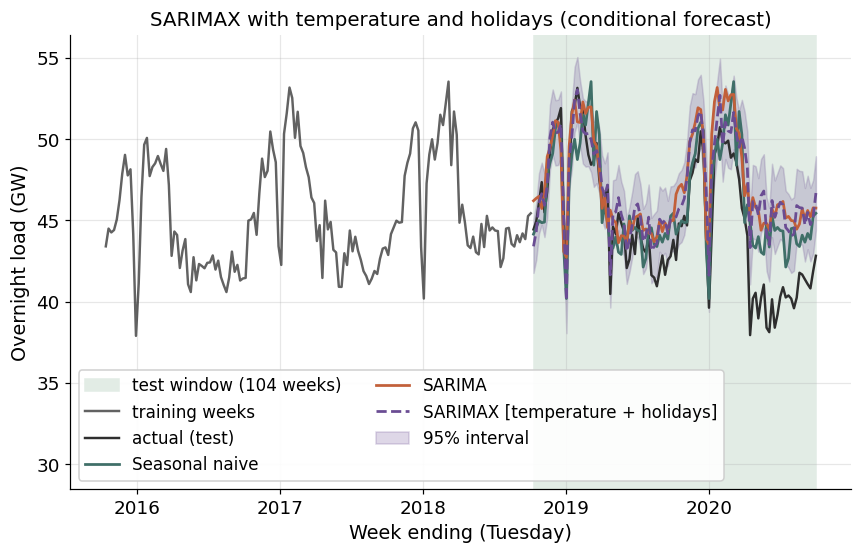

,Q,p_value
10,12.973,0.002
26,20.438,0.309


In [30]:
sx_main = "SARIMAX [temperature + holidays]"
sx_diag = sarima.residual_checks(sarimax_fits[sx_main])
facts["sarimax_lb10_p"] = sx_diag["ljung_box"].loc[10, "p_value"]
for name in [*SARIMAX_SETS, berlin_name]:
    facts[f"mase::{name}"] = sarimax_scores.loc[name, "MASE"]
facts["berlin_mae"] = sarimax_scores.loc[berlin_name, "MAE"]
facts["fivecity_mae"] = sarimax_scores.loc[sx_main, "MAE"]
facts["berlin_mase_delta"] = facts[f"mase::{berlin_name}"] - facts[f"mase::{sx_main}"]
facts["sarimax_cov"] = sarimax_scores.loc[sx_main, "Coverage95"]
fig = plotting.plot_paths(y_train, y_test,
                          {"Seasonal naive": paths["Seasonal naive"], "SARIMA": paths["SARIMA"],
                           sx_main: paths[sx_main]},
                          "SARIMAX with temperature and holidays (conditional forecast)",
                          bands={sx_main: bands[sx_main]}, legend_cols=2)
plotting.save_png(fig, "12_sarimax_forecast")
plt.show()
display(sx_diag["ljung_box"].round(4))

In [31]:
display(Markdown(render_findings(r"""
**SARIMAX result.** **Heating degree days carry the temperature effect («sarimax_hdd_coef» GW per sd, p = «sarimax_hdd_p»)**; cooling degree days matter much less («sarimax_cdd_coef» GW per sd, p = «sarimax_cdd_p»). Holidays lower overnight load («sarimax_hol_coef» GW per sd). Test MASE: «sarima_mase» with no covariates, «mase::SARIMAX [temperature]» with temperature, «mase::SARIMAX [holidays]» with holidays and **«mase::SARIMAX [temperature + holidays]» with both**. **Berlin only:** MASE «mase::SARIMAX [Berlin temperature + holidays]» (MAE «berlin_mae» GW) against «mase::SARIMAX [temperature + holidays]» (MAE «fivecity_mae» GW) for five cities, a change of «berlin_mase_delta». The covariates explain weekly ups and downs but not the level drop of 2019 to 2020.
""", facts)))


**SARIMAX result.** **Heating degree days carry the temperature effect (2.319 GW per sd, p = 6.4e-15)**; cooling degree days matter much less (0.339 GW per sd, p = 0.006). Holidays lower overnight load (-0.651 GW per sd). Test MASE: 1.773 with no covariates, 1.637 with temperature, 1.714 with holidays and **1.541 with both**. **Berlin only:** MASE 1.550 (MAE 2.31 GW) against 1.541 (MAE 2.29 GW) for five cities, a change of 0.009. The covariates explain weekly ups and downs but not the level drop of 2019 to 2020.


## Checkpoint 5 · Random forest and gradient boosting

**Features per week:**

* target lags of 1, 3, 13 and 52 weeks and rolling means of the previous 4 and 8 weeks, all built with `shift(1)`, so row *t* never sees week *t*;
* week-of-year sine and cosine, and the holiday count;
* temperature as either **realised** (this week's degree days and last week's mean, conditional) or **climatology** (training-week average for that week of the year, known in advance).

**Tuning:** `TimeSeriesSplit` with four folds on training rows only. **Forecast:** recursive, so each predicted week feeds the next week's lags. **Interval:** quantiles of the errors from a 52-week validation rollout. With only 52 errors this is a rough range, not an exact 95% interval.

In [32]:
# the climatology is a learned statistic, so it uses training weeks only
hdd_climate = features.climatology_hdd(train_df)
table = features.design_matrix(frame, hdd_climate)
main_cols = features.columns_for("realised weather + holidays")
fit_rows = table.loc[train_df.index].dropna(subset=main_cols)
facts["tree_train_rows"] = len(fit_rows)
print(f"Training rows after the 52-week lag warm-up: {len(fit_rows)}")
table.loc[train_df.index].dropna().head(3).round(2)

Training rows after the 52-week lag warm-up: 143


,lag_1,lag_3,lag_13,lag_52,roll_4,roll_8,woy_sin,woy_cos,holidays,hdd,cdd,temp_lag1,hdd_clim,overnight_gw
local_time,,,,,,,,,,,,,,
2016-01-12,41.11,44.17,43.41,45.93,42.83,45.28,0.24,0.97,0.0,104.46,0.0,-0.20,96.87,46.46
2016-01-19,46.46,37.90,44.50,46.18,42.41,45.31,0.35,0.94,0.0,122.56,0.0,1.08,101.44,49.66
2016-01-26,49.66,41.11,44.26,47.98,43.78,45.53,0.46,0.89,0.0,105.98,0.0,-1.51,101.02,50.08


In [33]:
t0 = time.perf_counter()
forest_params, forest_cv = tree_models.tune_on_folds(
    tree_models.forest_template, tree_models.FOREST_GRID, fit_rows[main_cols], fit_rows["overnight_gw"])
boost_params, boost_cv = tree_models.tune_on_folds(
    tree_models.boosting_template, tree_models.BOOSTING_GRID, fit_rows[main_cols], fit_rows["overnight_gw"])
timings["tree tuning (16 settings x 4 folds)"] = time.perf_counter() - t0
print("Random forest:", forest_params)
print("Gradient boosting:", boost_params)
display(forest_cv.head(4).round(3))
boost_cv.head(4).round(3)

Random forest: {'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 0.5}
Gradient boosting: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}


,max_depth,min_samples_leaf,max_features,cv_mae
0,8.0,1,0.5,1.183
1,NaN,1,0.5,1.195
2,NaN,3,0.5,1.220
3,8.0,3,0.5,1.221


,learning_rate,max_depth,n_estimators,cv_mae
0,0.03,2,200,1.132
1,0.03,2,500,1.145
2,0.03,3,200,1.163
3,0.03,3,500,1.167


In [34]:
# Four covariate sets per model separate the value of lags, holidays, realised weather
# and climatology. Only the realised-weather set is conditional.
TREE_LABELS = {"realised weather + holidays": "", "climatology + holidays": " [climatology + holidays]",
               "holidays only": " [holidays only]", "no covariates": " [no covariates]"}
tree_runs = {}
t0 = time.perf_counter()
for set_name, suffix in TREE_LABELS.items():
    cols = features.columns_for(set_name)
    for base, template in (("Random forest", tree_models.forest_template(**forest_params)),
                           ("Gradient boosting", tree_models.boosting_template(**boost_params))):
        name = base + suffix
        run = tree_models.recursive_with_band(template, table, train_df.index, test_df.index, cols, name)
        tree_runs[name] = run
        paths[name] = run.forecast
        bands[name] = pd.DataFrame({"lower": run.lower, "upper": run.upper})
timings["trees (8 fits + validation refits)"] = time.perf_counter() - t0
tree_scores = pd.DataFrame({n: ev.score_path(y_test, paths[n], MASE_SCALE, bands[n]["lower"],
                                             bands[n]["upper"]) for n in tree_runs}).T
for n in tree_runs:
    facts[f"mase::{n}"] = tree_scores.loc[n, "MASE"]
facts["rf_cov"] = tree_scores.loc["Random forest", "Coverage95"]
tree_scores.sort_values("MASE").round(3)

,MAE,RMSE,MAPE_pct,MASE,Bias,Coverage95
Gradient boosting,1.854,2.387,4.365,1.247,0.979,0.712
Random forest,1.868,2.390,4.387,1.257,0.863,0.663
Random forest [climatology + holidays],2.018,2.548,4.704,1.357,1.300,0.692
Gradient boosting [climatology + holidays],2.054,2.585,4.798,1.381,1.461,0.731
Random forest [holidays only],2.132,2.728,4.979,1.434,1.520,0.692
Random forest [no covariates],2.133,2.745,4.987,1.434,1.446,0.712
Gradient boosting [holidays only],2.145,2.688,4.998,1.442,1.483,0.721
Gradient boosting [no covariates],2.234,2.815,5.208,1.502,1.620,0.817


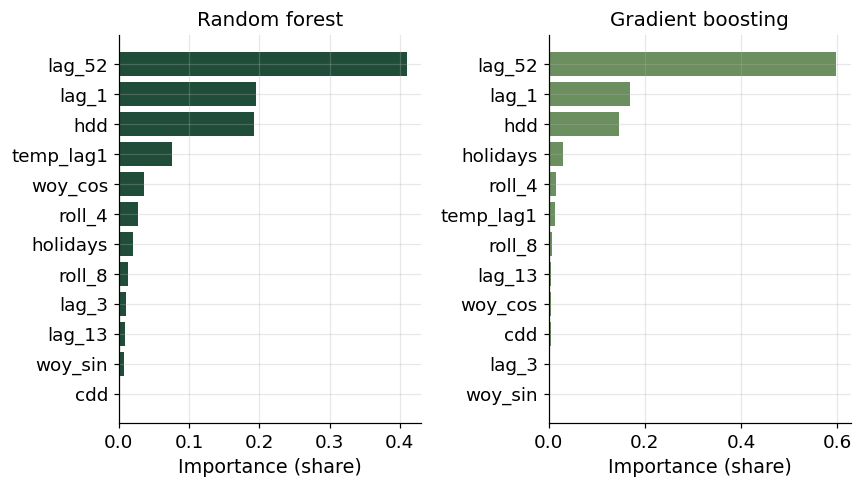

In [35]:
fig = plotting.plot_importance({"Random forest": tree_runs["Random forest"].importance,
                                "Gradient boosting": tree_runs["Gradient boosting"].importance})
plotting.save_png(fig, "13_tree_importance")
plt.show()
rf_imp = tree_runs["Random forest"].importance.sort_values(ascending=False)
facts["rf_top1"], facts["rf_top2"] = rf_imp.index[0], rf_imp.index[1]

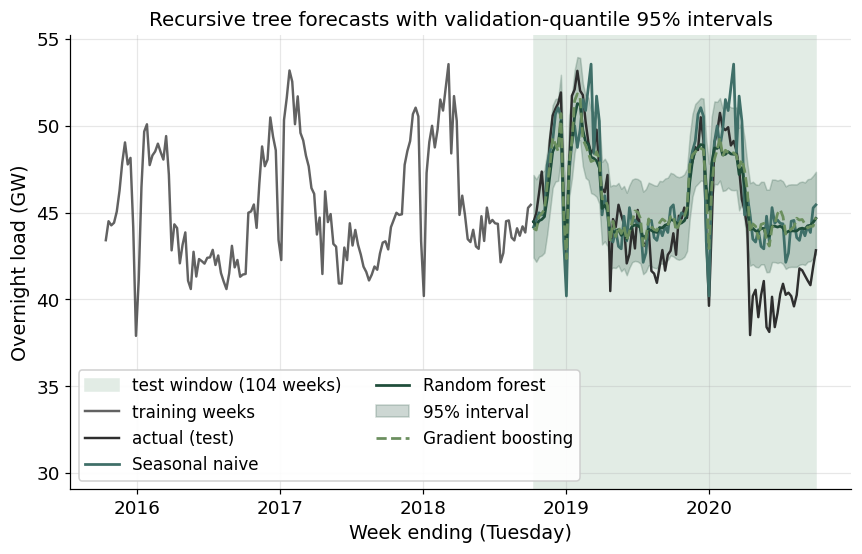

In [36]:
fig = plotting.plot_paths(y_train, y_test,
                          {"Seasonal naive": paths["Seasonal naive"], "Random forest": paths["Random forest"],
                           "Gradient boosting": paths["Gradient boosting"]},
                          "Recursive tree forecasts with validation-quantile 95% intervals",
                          bands={"Random forest": bands["Random forest"]}, legend_cols=2)
plotting.save_png(fig, "14_tree_forecasts")
plt.show()

In [37]:
display(Markdown(render_findings(r"""
**Tree models.** With realised weather and holidays, **the random forest reaches MASE «mase::Random forest»** and gradient boosting «mase::Gradient boosting». The forest relies most on `«rf_top1»` and `«rf_top2»`. With climatology instead of realised weather, the forest scores «mase::Random forest [climatology + holidays]», **the honest figure for real use**. Holidays only: «mase::Random forest [holidays only]»; no covariates: «mase::Random forest [no covariates]». The forest interval covers «rf_cov» of test weeks, below 95%, because its 52 validation weeks had no shock like the lockdown.
""", facts)))


**Tree models.** With realised weather and holidays, **the random forest reaches MASE 1.257** and gradient boosting 1.247. The forest relies most on `lag_52` and `lag_1`. With climatology instead of realised weather, the forest scores 1.357, **the honest figure for real use**. Holidays only: 1.434; no covariates: 1.434. The forest interval covers 0.66 of test weeks, below 95%, because its 52 validation weeks had no shock like the lockdown.


## Checkpoint 6 · Hourly LSTM (PyTorch)

**Why an LSTM.** LSTM cells (Hochreiter and Schmidhuber, 1997) keep a gated memory, so they can use a week or two of hourly history. In load forecasting, Marino, Amarasinghe and Manic (2016) used them for building load, Kong et al. (2019) for noisy household load, and Bouktif et al. (2018) tuned window and depth on French national load. All of these forecast hours to days ahead. **Two years ahead is harder, because errors feed back into the inputs**, so here the network is anchored to a seasonal profile.

**Design:**

* **Target:** hourly load minus a training-only profile (mean load per month x weekday x hour), scaled.
* **Inputs:** the scaled anomaly, sine and cosine of hour, weekday and day of year, and a holiday flag.
* **Output:** the next 24 hours from midnight.
* **Two-year forecast:** day by day, 728 times, each day written back into the input. Test-window load is blanked first, so nothing leaks.
* **Sweep:** window 168 or 336 h, hidden size 32 or 96, dropout 0.1 or 0.3, learning rate 0.003 or 0.001 (16 one-layer settings), then the two best rebuilt with two layers (18 in all). The last 26 training weeks are held out and the network is rolled over them after each epoch; training stops after 5 epochs without improvement.
* **Device:** CPU with fixed seeds, so the results repeat exactly. Set `NIGHTLOAD_DEVICE` to `mps` or `cuda` to use a GPU (the last decimals may then change).

In [38]:
DEVICE = lstm.choose_device()
lstm.pin_random_state()
LSTM_TEST_START = TEST_START - pd.Timedelta(days=6)  # Wednesday 00:00 of the first test week
LSTM_DAYS = 7 * cfg.TEST_WEEKS
print(f"Device: {DEVICE}; hourly test window starts {LSTM_TEST_START} and runs {LSTM_DAYS} days")

Device: cpu; hourly test window starts 2018-10-03 00:00:00 and runs 728 days


In [39]:
t0 = time.perf_counter()
sweep_table, sweep_curves, lstm_net = lstm.run_sweep(hourly["load_gw"], holiday_daily, LSTM_TEST_START, DEVICE)
timings["LSTM sweep (18 settings)"] = time.perf_counter() - t0
best_lstm = sweep_table.iloc[0]
facts.update(lstm_best_label=best_lstm["label"], lstm_val_mae=best_lstm["val_rollout_mae_gw"],
             lstm_sweep_minutes=timings["LSTM sweep (18 settings)"] / 60,
             lstm_train_samples=int(best_lstm["train_samples"]),
             lstm_val_start=str((LSTM_TEST_START - pd.Timedelta(days=cfg.LSTM_GRID.validation_days)).date()),
             lstm_best_layers=int(best_lstm["layers"]),
             lstm_two_layer_mae=float(sweep_table.loc[sweep_table["stage"] == 2, "val_rollout_mae_gw"].min()))
print(f"Validation block starts {facts['lstm_val_start']}; training samples (day-ahead windows): "
      f"{facts['lstm_train_samples']:,}")
sweep_table.round(4)

  [ 1] w168_h32_d0.1_lr0.003_L1     rollout MAE 1.982 GW  best epoch  6 of 11  5 s


  [ 2] w168_h32_d0.1_lr0.001_L1     rollout MAE 2.152 GW  best epoch  8 of 13  5 s


  [ 3] w168_h32_d0.3_lr0.003_L1     rollout MAE 2.079 GW  best epoch  6 of 11  4 s


  [ 4] w168_h32_d0.3_lr0.001_L1     rollout MAE 2.202 GW  best epoch  8 of 13  5 s


  [ 5] w168_h96_d0.1_lr0.003_L1     rollout MAE 1.628 GW  best epoch  8 of 13  10 s


  [ 6] w168_h96_d0.1_lr0.001_L1     rollout MAE 2.118 GW  best epoch  6 of 11  8 s


... (10 outputs left out)

  [17] w168_h96_d0.1_lr0.003_L2     rollout MAE 1.920 GW  best epoch  4 of  9  14 s


  [18] w336_h32_d0.1_lr0.001_L2     rollout MAE 1.782 GW  best epoch  3 of  8  13 s


Validation block starts 2018-04-04; training samples (day-ahead windows): 1,180


,stage,label,train_samples,val_samples,window,hidden,dropout,lr,layers,best_epoch,epochs_run,val_mse_scaled,val_rollout_mae_gw,seconds
0,1,w168_h96_d0.1_lr0.003_L1,1180,181,168,96,0.1,0.003,1,8,13,0.283,1.628,9.5
1,2,w336_h32_d0.1_lr0.001_L2,1173,181,336,32,0.1,0.001,2,3,8,0.445,1.782,13.2
2,1,w336_h32_d0.1_lr0.001_L1,1173,181,336,32,0.1,0.001,1,3,8,0.456,1.812,6.3
3,2,w168_h96_d0.1_lr0.003_L2,1180,181,168,96,0.1,0.003,2,4,9,0.325,1.920,13.8
4,1,w168_h96_d0.3_lr0.003_L1,1180,181,168,96,0.3,0.003,1,6,11,0.303,1.974,8.0
5,1,w168_h32_d0.1_lr0.003_L1,1180,181,168,32,0.1,0.003,1,6,11,0.307,1.982,5.0
6,1,w336_h96_d0.1_lr0.001_L1,1173,181,336,96,0.1,0.001,1,3,8,0.421,2.013,11.5
7,1,w336_h96_d0.3_lr0.003_L1,1173,181,336,96,0.3,0.003,1,1,6,0.449,2.030,8.6
8,1,w336_h96_d0.3_lr0.001_L1,1173,181,336,96,0.3,0.001,1,3,8,0.418,2.045,11.5
9,1,w168_h32_d0.3_lr0.003_L1,1180,181,168,32,0.3,0.003,1,6,11,0.313,2.079,4.4


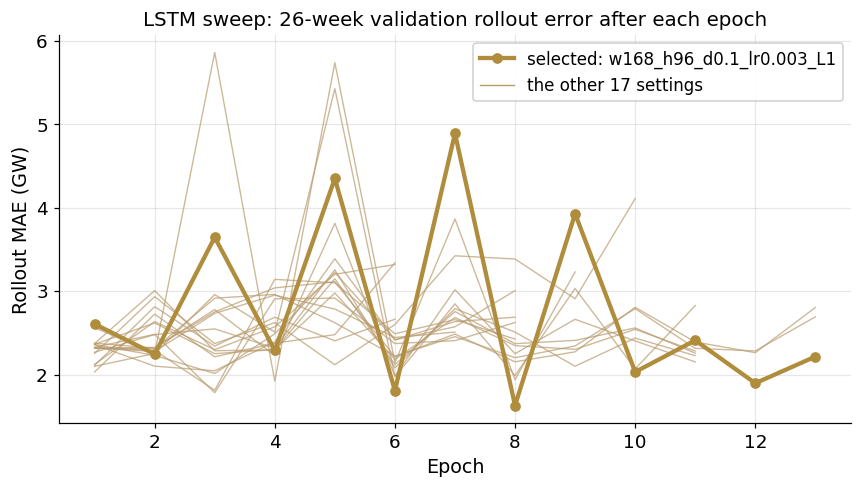

In [40]:
fig = plotting.plot_lstm_curves(sweep_curves, best_lstm["label"])
plotting.save_png(fig, "15_lstm_sweep_curves")
plt.show()

In [41]:
t0 = time.perf_counter()
lstm_hourly, profile_hourly = lstm.forecast_test(lstm_net, hourly["load_gw"], holiday_daily,
                                                 LSTM_TEST_START, LSTM_DAYS, int(best_lstm.window), DEVICE)
timings["LSTM 728-day test rollout"] = time.perf_counter() - t0
actual_hourly = hourly["load_gw"].reindex(lstm_hourly.index)
hourly_scores = pd.DataFrame({
    name: {"hourly MAE (GW)": float((p - actual_hourly).abs().mean()),
           "hourly RMSE (GW)": float(np.sqrt(((p - actual_hourly) ** 2).mean())),
           "hourly MAPE (%)": float(((p - actual_hourly).abs() / actual_hourly).mean() * 100)}
    for name, p in (("LSTM", lstm_hourly), ("Seasonal profile", profile_hourly))}).T
facts["lstm_hourly_mae"] = hourly_scores.loc["LSTM", "hourly MAE (GW)"]
# A recursive rollout should be best near the origin and fade, so split the error by horizon.
horizon_day = np.asarray((lstm_hourly.index - LSTM_TEST_START).days)
bucket = pd.cut(horizon_day, [-1, 6, 27, 364, LSTM_DAYS], labels=["days 1-7", "days 8-28", "days 29-365", "year 2"])
by_horizon = pd.DataFrame({"LSTM": (lstm_hourly - actual_hourly).abs().to_numpy(),
                           "Seasonal profile": (profile_hourly - actual_hourly).abs().to_numpy()}
                          ).groupby(np.asarray(bucket)).mean().loc[["days 1-7", "days 8-28", "days 29-365", "year 2"]]
facts["lstm_h1_mae"], facts["profile_h1_mae"] = by_horizon.loc["days 1-7"]
facts["lstm_y2_mae"], facts["profile_y2_mae"] = by_horizon.loc["year 2"]
facts["lstm_m1_mae"], facts["profile_m1_mae"] = by_horizon.loc["days 8-28"]
facts["lstm_y1_mae"], facts["profile_y1_mae"] = by_horizon.loc["days 29-365"]
lstm_wins = [b for b in by_horizon.index if by_horizon.loc[b, "LSTM"] < by_horizon.loc[b, "Seasonal profile"]]
lstm_loses = [b for b in by_horizon.index if b not in lstm_wins]
def as_list(items):
    """Join labels as 'a', 'a and b' or 'a, b and c'."""
    return "no horizon band" if not items else (
        items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1])

facts["lstm_horizon_verdict"] = (f"The network beats its own profile over {as_list(lstm_wins)} "
                                 f"and loses to it over {as_list(lstm_loses)}.")
display(by_horizon.round(3).rename_axis("hourly MAE (GW) by horizon"))
facts["profile_hourly_mae"] = hourly_scores.loc["Seasonal profile", "hourly MAE (GW)"]
n_params = sum(p.numel() for p in lstm_net.parameters())
facts["lstm_params"] = n_params
print(f"Selected network: {best_lstm['label']}, best epoch {int(best_lstm['best_epoch'])}, "
      f"trainable parameters: {n_params:,}")
hourly_scores.round(3)

,LSTM,Seasonal profile
hourly MAE (GW) by horizon,,
days 1-7,2.945,2.639
days 8-28,1.939,2.186
days 29-365,2.381,2.552
year 2,3.483,2.767


Selected network: w168_h96_d0.1_lr0.003_L1, best epoch 8, trainable parameters: 43,104


,hourly MAE (GW),hourly RMSE (GW),hourly MAPE (%)
LSTM,2.923,4.301,5.616
Seasonal profile,2.649,3.914,4.998


In [42]:
# The other models forecast weekly overnight means, so the hourly LSTM output is binned
# with exactly the same lens before it is scored against them.
def overnight_weekly(hours: pd.Series) -> pd.Series:
    """Weekly W-TUE mean of the 00:00-05:59 hours of an hourly series."""
    night = hours[hours.index.hour.isin(cfg.OVERNIGHT_HOURS)]
    return night.resample(cfg.WEEK_RULE).mean().reindex(y_test.index)

paths["LSTM"] = overnight_weekly(lstm_hourly).rename("LSTM")
paths["Seasonal profile"] = overnight_weekly(profile_hourly).rename("Seasonal profile")
lstm_weekly = pd.DataFrame({n: ev.score_path(y_test, paths[n], MASE_SCALE) for n in ("LSTM", "Seasonal profile")}).T
facts["mase::LSTM"] = lstm_weekly.loc["LSTM", "MASE"]
facts["mase::Seasonal profile"] = lstm_weekly.loc["Seasonal profile", "MASE"]
snaive_mase_now = ev.score_path(y_test, paths["Seasonal naive"], MASE_SCALE)["MASE"]
def versus(mase: float) -> str:
    """'beats' / 'matches' / 'does not beat' the seasonal naive, with a 2% band for 'matches'."""
    ratio = mase / snaive_mase_now
    return "beats" if ratio < 0.98 else "matches" if ratio <= 1.02 else "does not beat"

lstm_vs = versus(facts["mase::LSTM"])
prof_vs = versus(facts["mase::Seasonal profile"])
lead = "LSTM" if facts["mase::LSTM"] < facts["mase::Seasonal profile"] else "bare seasonal profile"
facts["lstm_weekly_verdict"] = (f"the LSTM {lstm_vs} the seasonal naive (MASE {snaive_mase_now:.3f}), the profile alone "
                                f"{prof_vs} it, and the {lead} is the better of the two")
lstm_weekly.round(3)

,MAE,RMSE,MAPE_pct,MASE,Bias,Coverage95
LSTM,2.011,2.630,4.656,1.352,1.211,NaN
Seasonal profile,1.812,2.331,4.068,1.219,-0.152,NaN


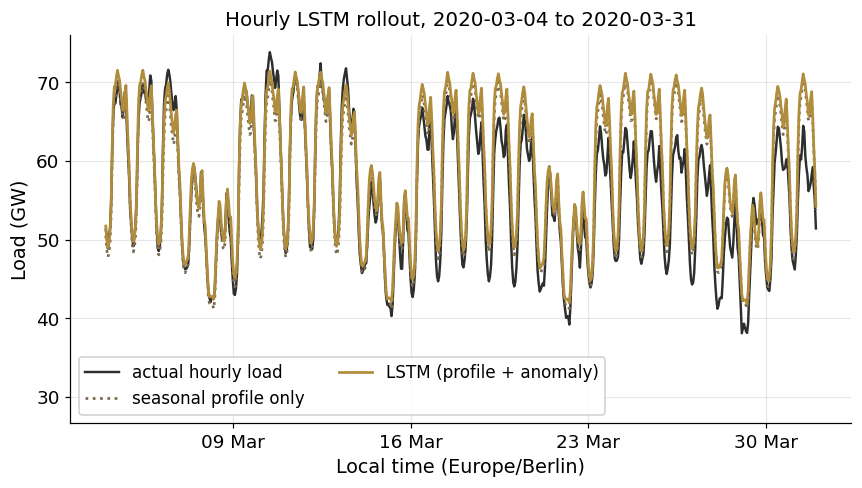

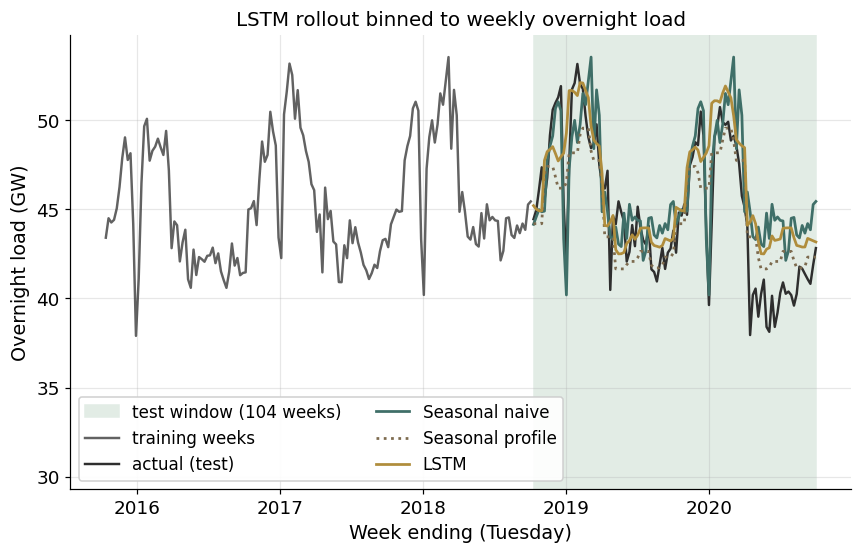

In [43]:
fig = plotting.plot_hourly_slice(actual_hourly, lstm_hourly, profile_hourly, "2020-03-04", "2020-03-31")
plotting.save_png(fig, "16_lstm_hourly_lockdown")
plt.show()
fig = plotting.plot_paths(y_train, y_test, {"Seasonal naive": paths["Seasonal naive"],
                                            "Seasonal profile": paths["Seasonal profile"], "LSTM": paths["LSTM"]},
                          "LSTM rollout binned to weekly overnight load", legend_cols=2)
plotting.save_png(fig, "17_lstm_weekly")
plt.show()

In [44]:
display(Markdown(render_findings(r"""
**LSTM result.** The sweep took «lstm_sweep_minutes» min and picked **«lstm_best_label»** (validation MAE «lstm_val_mae» GW; best two-layer «lstm_two_layer_mae» GW). **Hourly test MAE: «lstm_hourly_mae» GW** against «profile_hourly_mae» GW for the profile alone.

By horizon (LSTM vs profile, GW): first week «lstm_h1_mae» vs «profile_h1_mae»; days 8 to 28 «lstm_m1_mae» vs «profile_m1_mae»; rest of year one «lstm_y1_mae» vs «profile_y1_mae»; year two «lstm_y2_mae» vs «profile_y2_mae». **«lstm_horizon_verdict»**

The validation error jumps by several GW between epochs, so the chosen setting carries some luck. **On the weekly series the LSTM reaches MASE «mase::LSTM» and the profile alone «mase::Seasonal profile»: «lstm_weekly_verdict».** Most of the forecastable structure is the month x weekday x hour shape. No model here could foresee the March 2020 lockdown.
""", facts)))


**LSTM result.** The sweep took 2.4 min and picked **w168_h96_d0.1_lr0.003_L1** (validation MAE 1.63 GW; best two-layer 1.78 GW). **Hourly test MAE: 2.92 GW** against 2.65 GW for the profile alone.

By horizon (LSTM vs profile, GW): first week 2.95 vs 2.64; days 8 to 28 1.94 vs 2.19; rest of year one 2.38 vs 2.55; year two 3.48 vs 2.77. **The network beats its own profile over days 8-28 and days 29-365 and loses to it over days 1-7 and year 2.**

The validation error jumps by several GW between epochs, so the chosen setting carries some luck. **On the weekly series the LSTM reaches MASE 1.352 and the profile alone 1.219: the LSTM matches the seasonal naive (MASE 1.355), the profile alone beats it, and the bare seasonal profile is the better of the two.** Most of the forecastable structure is the month x weekday x hour shape. No model here could foresee the March 2020 lockdown.


## Checkpoint 7 · Comparison table and master plot

Every model is scored on the same 104 weeks: **MAE, RMSE, MAPE, MASE, bias** (positive = over-forecast) and **95% interval coverage**. `MASE_vs_snaive` below 1 beats the seasonal naive. The **Diebold-Mariano test** compares each model with the seasonal naive, using a 12-lag Newey-West window (`DM_p`) and a 4-lag window as a check (`DM_p_bw4`). `known_at_origin` is False for models that use realised test-window temperature.

In [45]:
ORIGIN_KNOWN = {n: not ("temperature" in n or n in ("Random forest", "Gradient boosting"))
                for n in paths}
FAMILY = {n: ("benchmark" if n in ("Mean", "Naive", "Seasonal naive", "Drift") else
              "statistical" if n.startswith("SARIMA") else
              "neural" if n == "LSTM" else "profile (LSTM baseline)" if n == "Seasonal profile" else "feature ML") for n in paths}
scoreboard = ev.league_table(y_test, paths, bands, MASE_SCALE, origin_known=ORIGIN_KNOWN)
scoreboard.insert(0, "family", scoreboard.index.map(FAMILY))
scoreboard.round(3)

,family,MAE,RMSE,MAPE_pct,MASE,Bias,Coverage95,DM_stat,DM_p,DM_p_bw4,known_at_origin,MASE_vs_snaive
model,,,,,,,,,,,,
Seasonal profile,profile (LSTM baseline),1.812,2.331,4.068,1.219,-0.152,NaN,-0.542,0.589,0.483,True,0.899
Gradient boosting,feature ML,1.854,2.387,4.365,1.247,0.979,0.712,-1.246,0.216,0.186,False,0.920
Random forest,feature ML,1.868,2.390,4.387,1.257,0.863,0.663,-1.214,0.228,0.231,False,0.927
LSTM,neural,2.011,2.630,4.656,1.352,1.211,NaN,0.148,0.882,0.879,True,0.998
Seasonal naive,benchmark,2.015,2.579,4.674,1.355,1.235,0.952,NaN,NaN,NaN,True,1.000
Random forest [climatology + holidays],feature ML,2.018,2.548,4.704,1.357,1.300,0.692,-0.392,0.696,0.773,True,1.001
Gradient boosting [climatology + holidays],feature ML,2.054,2.585,4.798,1.381,1.461,0.731,0.061,0.952,0.953,True,1.019
Random forest [holidays only],feature ML,2.132,2.728,4.979,1.434,1.520,0.692,0.965,0.337,0.421,True,1.058
Random forest [no covariates],feature ML,2.133,2.745,4.987,1.434,1.446,0.712,1.103,0.273,0.387,True,1.059


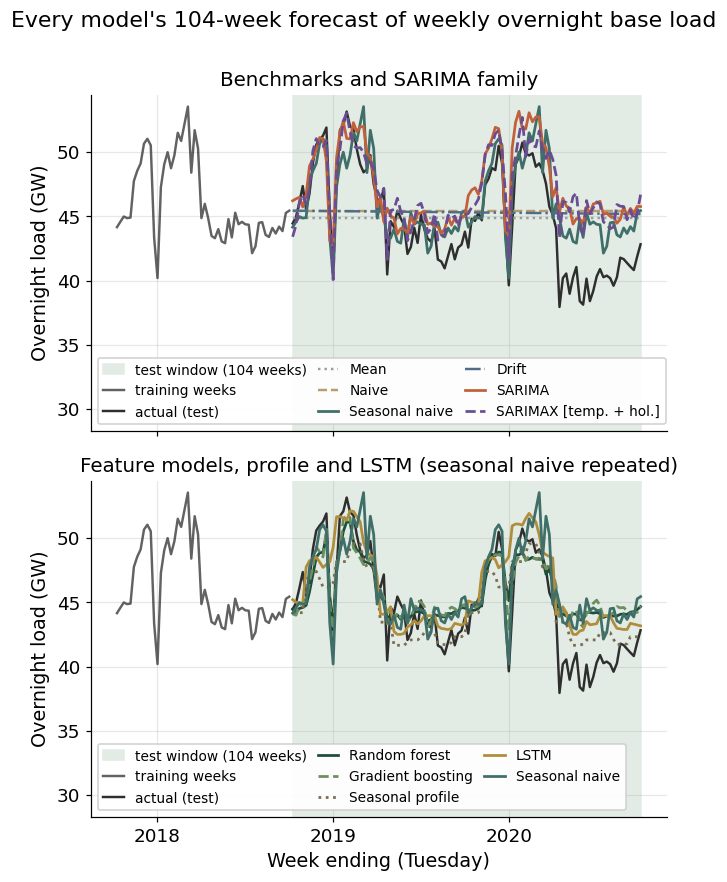

In [46]:
MAIN_MODELS = ["Mean", "Naive", "Seasonal naive", "Drift", "SARIMA", "SARIMAX [temperature + holidays]",
               "Random forest", "Gradient boosting", "Seasonal profile", "LSTM"]
fig = plotting.plot_master(y_train, y_test, {n: paths[n] for n in MAIN_MODELS})
plotting.save_png(fig, "18_master_forecasts")
plt.show()

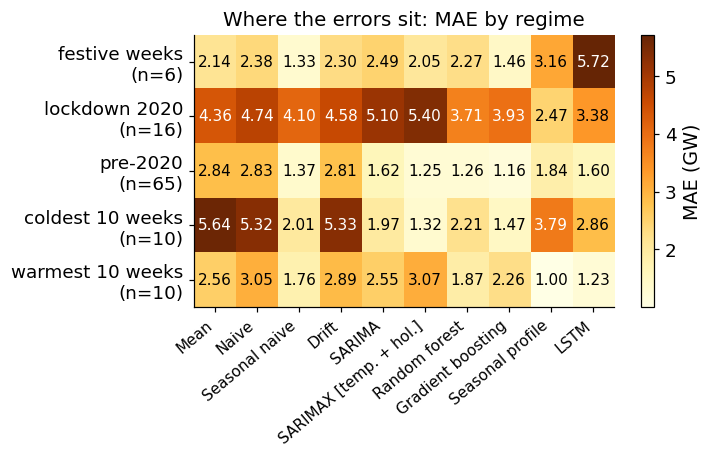

,Mean,Naive,Seasonal naive,Drift,SARIMA,SARIMAX [temperature + holidays],Random forest,Gradient boosting,Seasonal profile,LSTM,weeks
festive weeks,2.143,2.384,1.335,2.298,2.492,2.045,2.273,1.458,3.161,5.719,6.0
lockdown 2020 (17 Mar to 30 Jun),4.365,4.742,4.103,4.580,5.096,5.400,3.710,3.935,2.473,3.382,16.0
pre-2020,2.837,2.830,1.370,2.807,1.620,1.250,1.260,1.162,1.841,1.603,65.0
coldest 10 weeks,5.641,5.318,2.007,5.328,1.971,1.317,2.208,1.472,3.791,2.855,10.0
warmest 10 weeks,2.560,3.049,1.762,2.888,2.553,3.070,1.874,2.265,1.004,1.225,10.0


In [47]:
regimes = ev.regime_errors(y_test, {n: paths[n] for n in MAIN_MODELS}, frame)
fig = plotting.plot_regime_heat(regimes)
plotting.save_png(fig, "19_regime_mae")
plt.show()
facts["lockdown_snaive_mae"] = regimes.loc["lockdown 2020 (17 Mar to 30 Jun)", "Seasonal naive"]
facts["pre2020_snaive_mae"] = regimes.loc["pre-2020", "Seasonal naive"]
body = regimes.drop(columns="weeks")
facts["festive_worst"] = body.loc["festive weeks"].idxmax()
facts["festive_worst_mae"] = body.loc["festive weeks"].max()
facts["cold_best"] = body.loc["coldest 10 weeks"].idxmin()
facts["cold_best_mae"] = body.loc["coldest 10 weeks"].min()
facts["lockdown_best"] = body.loc["lockdown 2020 (17 Mar to 30 Jun)"].idxmin()
facts["lockdown_best_mae"] = body.loc["lockdown 2020 (17 Mar to 30 Jun)"].min()
regimes.round(3)

In [48]:
best_name = scoreboard.index[0]
facts.update(n_overforecast=int((scoreboard["Bias"] > 0).sum()), n_models=len(scoreboard))
best_known = scoreboard[scoreboard["known_at_origin"]].index[0]
facts.update(best_model=best_name, best_mase=scoreboard.loc[best_name, "MASE"],
             best_ratio=scoreboard.loc[best_name, "MASE_vs_snaive"],
             best_known_model=best_known, best_known_mase=scoreboard.loc[best_known, "MASE"],
             best_known_ratio=scoreboard.loc[best_known, "MASE_vs_snaive"])
for n in scoreboard.index:
    facts[f"row::{n}"] = scoreboard.loc[n].drop("family").to_dict()
print(f"Lowest MASE overall: {best_name} ({facts['best_mase']:.3f}, ratio {facts['best_ratio']:.3f})")
print(f"Lowest MASE using only inputs known at the origin: {best_known} "
      f"({facts['best_known_mase']:.3f}, ratio {facts['best_known_ratio']:.3f})")

Lowest MASE overall: Seasonal profile (1.219, ratio 0.899)
Lowest MASE using only inputs known at the origin: Seasonal profile (1.219, ratio 0.899)


In [49]:
display(Markdown(render_findings(r"""
**Scoreboard.** **«best_model» has the lowest MASE («best_mase», «best_ratio» of the seasonal naive).** Using only inputs known in advance, the best is **«best_known_model»** (MASE «best_known_mase»). The seasonal profile is the LSTM's baseline, scored on its own so the network's extra value can be seen.

**Shared failure:** the models learned the higher 2015 to 2018 level, so **«n_overforecast» of «n_models» models over-forecast**, most in the 2020 lockdown (seasonal naive MAE «lockdown_snaive_mae» GW then, «pre2020_snaive_mae» GW before 2020). Largest festive-week error: «festive_worst» («festive_worst_mae» GW). Best in the ten coldest weeks: «cold_best» («cold_best_mae» GW). Smallest lockdown error: «lockdown_best» («lockdown_best_mae» GW).
""", facts)))


**Scoreboard.** **Seasonal profile has the lowest MASE (1.219, 0.899 of the seasonal naive).** Using only inputs known in advance, the best is **Seasonal profile** (MASE 1.219). The seasonal profile is the LSTM's baseline, scored on its own so the network's extra value can be seen.

**Shared failure:** the models learned the higher 2015 to 2018 level, so **18 of 19 models over-forecast**, most in the 2020 lockdown (seasonal naive MAE 4.10 GW then, 1.37 GW before 2020). Largest festive-week error: LSTM (5.72 GW). Best in the ten coldest weeks: SARIMAX [temperature + holidays] (1.32 GW). Smallest lockdown error: Seasonal profile (2.47 GW).


## Checkpoint 8 · Extra checks

Four short checks used in the report: **the improvement rule, a leakage test, model size and run time, and the operational shortlist.** Their values are saved in `facts`.

In [50]:
# Improvement rule: MASE at least 5% below the seasonal naive AND a negative DM
# statistic with p below 0.05 (12-lag window); the 4-lag window is shown as a check.
cands = scoreboard.drop(index="Seasonal naive")
gain = (cands["MASE_vs_snaive"] <= 0.95) & (cands["DM_stat"] < 0)
facts["meaningful_gain"] = list(cands.index[gain & (cands["DM_p"] < 0.05)])
facts["meaningful_gain_bw4"] = list(cands.index[gain & (cands["DM_p_bw4"] < 0.05)])
facts["beats_snaive"] = list(cands.index[cands["MASE_vs_snaive"] < 1.0])
last_year = y_train.iloc[-cfg.SEASON:].mean()
facts.update(last_train_year_mean=last_year, train_mean=y_train.mean(), test_mean=y_test.mean())

print("Meaningful gain, 12-lag DM:", facts["meaningful_gain"] or "none")
print("Meaningful gain, 4-lag DM: ", facts["meaningful_gain_bw4"] or "none")
print(f"Test mean {y_test.mean():.2f} GW | last training year {last_year:.2f} GW")
display(cands[["MASE_vs_snaive", "DM_p", "DM_p_bw4"]].round(3))

Meaningful gain, 12-lag DM: none
Meaningful gain, 4-lag DM:  none
Test mean 44.90 GW | last training year 46.13 GW


,MASE_vs_snaive,DM_p,DM_p_bw4
model,,,
Seasonal profile,0.899,0.589,0.483
Gradient boosting,0.920,0.216,0.186
Random forest,0.927,0.228,0.231
LSTM,0.998,0.882,0.879
Random forest [climatology + holidays],1.001,0.696,0.773
Gradient boosting [climatology + holidays],1.019,0.952,0.953
Random forest [holidays only],1.058,0.337,0.421
Random forest [no covariates],1.059,0.273,0.387
Gradient boosting [holidays only],1.065,0.301,0.360


In [51]:
# Leakage test: replace every test-window load value with noise and rerun the forest
# rollout. If no actual value reaches a feature, the forecast does not change.
probe = table.copy()
rng = np.random.default_rng(0)
probe.loc[test_df.index, "overnight_gw"] = rng.normal(0, 100, len(test_df))
probe_path = tree_models.roll_weeks_ahead(tree_runs["Random forest"].model, probe["overnight_gw"].loc[train_df.index],
                                          probe.loc[test_df.index], main_cols)
leak_gap = float((probe_path - paths["Random forest"]).abs().max())
facts["leak_probe_max_diff"] = leak_gap
print(f"Largest change in the forest forecast: {leak_gap:.2e} GW")

Largest change in the forest forecast: 1.42e-14 GW


In [52]:
# Model size (stored values, parameters or tree nodes) next to accuracy, plus run times.
rf_nodes = sum(t.tree_.node_count for t in tree_runs["Random forest"].model.estimators_)
gb_nodes = sum(t[0].tree_.node_count for t in tree_runs["Gradient boosting"].model.estimators_)
facts.update(rf_nodes=rf_nodes, gb_nodes=gb_nodes)
size_rows = {"Seasonal naive": cfg.SEASON,  # the 52 weekly values it repeats
             "SARIMA": facts["sarima_params"], sx_main: len(sarimax_fits[sx_main].result.params),
             "Random forest": rf_nodes, "Gradient boosting": gb_nodes,
             "Seasonal profile": 12 * 7 * 24, "LSTM": facts["lstm_params"]}
complexity = pd.DataFrame({"size": size_rows, "MASE": scoreboard.loc[list(size_rows), "MASE"]})
display(complexity.round(3))
display(pd.Series(timings, name="seconds").round(1).to_frame())

,size,MASE
Seasonal naive,52,1.355
SARIMA,9,1.773
SARIMAX [temperature + holidays],12,1.541
Random forest,52526,1.257
Gradient boosting,1392,1.247
Seasonal profile,2016,1.219
LSTM,43104,1.352


,seconds
SARIMA grid (147 fits),301.4
SARIMA final fit,4.1
SARIMAX (3 variants + Berlin check),17.5
tree tuning (16 settings x 4 folds),6.8
trees (8 fits + validation refits),18.6
LSTM sweep (18 settings),145.9
LSTM 728-day test rollout,0.8


In [53]:
# Operational shortlist: only inputs known at the forecast origin, and an interval.
usable = scoreboard[scoreboard["known_at_origin"] & scoreboard["Coverage95"].notna()]
pick = usable.index[0]
better_known = scoreboard[scoreboard["known_at_origin"] & (scoreboard["MASE"] < usable.loc[pick, "MASE"])]
facts.update(operational_pick=pick, operational_pick_mase=usable.loc[pick, "MASE"],
             operational_pick_cov=usable.loc[pick, "Coverage95"],
             operational_rival=better_known.index[0] if len(better_known) else None)
print("Best model with origin-known inputs and an interval:", pick)
display(usable[["MASE", "MASE_vs_snaive", "Coverage95"]].round(3))

Best model with origin-known inputs and an interval: Seasonal naive


,MASE,MASE_vs_snaive,Coverage95
model,,,
Seasonal naive,1.355,1.000,0.952
Random forest [climatology + holidays],1.357,1.001,0.692
Gradient boosting [climatology + holidays],1.381,1.019,0.731
Random forest [holidays only],1.434,1.058,0.692
Random forest [no covariates],1.434,1.059,0.712
Gradient boosting [holidays only],1.442,1.065,0.721
Gradient boosting [no covariates],1.502,1.109,0.817
SARIMAX [holidays],1.714,1.265,0.577
SARIMA,1.773,1.308,0.577


## Checkpoint 9 · Output files

Forecasts, tables and a JSON of every number used in the text go to `outputs/`. Figures were saved to `figures/` as they were drawn.

In [54]:
forecast_table = pd.DataFrame({"actual": y_test, **{n: p.reindex(y_test.index) for n, p in paths.items()}})
forecast_table.to_csv(cfg.OUTPUT_DIR / "all_forecasts.csv", index_label="week_ending")
scoreboard.to_csv(cfg.OUTPUT_DIR / "model_comparison.csv", index_label="model")
regimes.to_csv(cfg.OUTPUT_DIR / "regime_mae.csv", index_label="regime")
sweep_table.to_csv(cfg.OUTPUT_DIR / "lstm_sweep.csv", index=False)
hourly_scores.to_csv(cfg.OUTPUT_DIR / "lstm_hourly_scores.csv", index_label="model")
pd.concat({"weekly": weekly_battery, "daily": daily_battery}).to_csv(cfg.OUTPUT_DIR / "stationarity.csv")
facts["timings_seconds"] = timings

def jsonable(value):
    """Make numpy scalars JSON-friendly."""
    if isinstance(value, dict):
        return {k: jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [jsonable(v) for v in value]
    if isinstance(value, (np.floating, np.integer, np.bool_)):
        return value.item()
    return value

(cfg.OUTPUT_DIR / "run_facts.json").write_text(json.dumps(jsonable(facts), indent=1))
for folder in (cfg.OUTPUT_DIR, cfg.FIGURE_DIR):
    names = sorted(p.name for p in folder.iterdir() if not p.name.startswith("."))
    print(f"{folder.name}/: {len(names)} files")
    print("   " + ", ".join(names))

outputs/: 9 files
   all_forecasts.csv, lstm_hourly_scores.csv, lstm_sweep.csv, model_comparison.csv, regime_mae.csv, run_facts.json, sarima_aic_grid.csv, sarima_aic_grid.meta.json, stationarity.csv
figures/: 19 files
   01_overnight_vs_all_hours.png, 02_daily_and_hourly.png, 03_temperature_response.png, 04_stl_weekly.png, 05_mstl_daily.png, 06_acf_pacf_weekly.png, 07_acf_pacf_daily.png, 08_benchmarks.png, 09_aic_surface.png, 10_sarima_residuals.png, 11_sarima_forecast.png, 12_sarimax_forecast.png, 13_tree_importance.png, 14_tree_forecasts.png, 15_lstm_sweep_curves.png, 16_lstm_hourly_lockdown.png, 17_lstm_weekly.png, 18_master_forecasts.png, 19_regime_mae.png
